# Final Notebook

## Setup Library

In [ ]:
%pip install -q bertopic 

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["USE_TF"] = "0"

import gc
import re
import copy
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sentence_transformers import SentenceTransformer

from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed: int = SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
})
sns.set_style("whitegrid")

print(f"Device aktif : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")


I0000 00:00:1795873681.287600      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Device aktif : cuda
PyTorch      : 2.11.0+cu130


## Load dataset & Split dataset

In [ ]:
DATA_CANDIDATES = [
    Path("../data/processed/merged_data.csv"),
    Path("../data/processed/merged_data_clean.csv"),
    Path("/kaggle/input/datasets/graceee12/process-dataset/processed/merged_data_clean.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Tidak menemukan data/processed/merged_data_clean.csv!")

df = pd.read_csv(DATA_PATH)
date_col = "Tanggal_dt" if "Tanggal_dt" in df.columns else "tanggal"
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

if "rate_mid" not in df.columns:
    df["rate_mid"] = (df["Kurs Jual"] + df["Kurs Beli"]) / 2.0

df["log_ret"] = np.log(df["rate_mid"] / df["rate_mid"].shift(1))
df = df.dropna(subset=["log_ret"]).reset_index(drop=True)
df["y_dir"] = (df["log_ret"] > 0).astype(int)

def clean_text_keep_case(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["title_clean"] = df["all_title"].fillna("").apply(clean_text_keep_case)
df["norm_clean"] = df["all_normalized_text"].fillna("").apply(clean_text_keep_case)
df["has_news"] = (df["news_count"].fillna(0) > 0).astype(int)

# SPLIT KRONOLOGIS DI AWAL (70% Train / 15% Val / 15% Test)
n_total = len(df)
train_end_idx = int(n_total * 0.70)
val_end_idx = int(n_total * 0.85)

df["split"] = "test"
df.loc[:train_end_idx - 1, "split"] = "train"
df.loc[train_end_idx:val_end_idx - 1, "split"] = "val"

train_end_date = df.loc[train_end_idx - 1, date_col]
val_end_date = df.loc[val_end_idx - 1, date_col]

is_tr = (df["split"] == "train").values
is_va = (df["split"] == "val").values
is_te = (df["split"] == "test").values

y_tr_dir = df.loc[is_tr, "y_dir"].values
y_va_dir = df.loc[is_va, "y_dir"].values
y_te_dir = df.loc[is_te, "y_dir"].values

print(f"Data path: {DATA_PATH}")
print(f"Dataset  : {n_total:,} hari perdagangan valid")
for sp, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    print(
        f"  {sp:5s}: {len(sub):4d} hari | {sub[date_col].min().date()} s/d {sub[date_col].max().date()} "
        f"| Naik={sub['y_dir'].mean()*100:.1f}% | Ada Berita={sub['has_news'].mean()*100:.1f}%"
    )

Data path: /kaggle/input/datasets/graceee12/process-dataset/processed/merged_data_clean.csv
Dataset  : 1,201 hari perdagangan valid
  Train:  840 hari | 2021-09-02 s/d 2025-02-18 | Naik=55.4% | Ada Berita=86.1%
  Val  :  180 hari | 2025-02-19 s/d 2025-11-21 | Naik=53.3% | Ada Berita=88.9%
  Test :  181 hari | 2025-11-24 s/d 2026-09-01 | Naik=57.5% | Ada Berita=97.8%


## Embedding Title

In [5]:
def extract_daily_title_embeddings(
    model_name: str,
    unique_titles: list,
    title_lists,
    batch_size: int = 128,
    max_len: int = 48,
    cache_path: str = None,
):
    if cache_path and os.path.exists(cache_path):
        print(f"Memuat cache embedding dari {cache_path}")
        data = np.load(cache_path, allow_pickle=True)
        title_emb_map = dict(zip(data["titles"].tolist(), data["embs"]))
    else:
        print(f"Memuat frozen model untuk embedding judul: {model_name} (device={DEVICE}) ...")
        tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
        mdl = AutoModel.from_pretrained(model_name).to(DEVICE)
        mdl.eval()
        for p in mdl.parameters():
            p.requires_grad = False

        use_amp = str(DEVICE).startswith("cuda")

        # Urutkan berdasarkan panjang teks agar padding minimal (lebih cepat)
        order = sorted(range(len(unique_titles)), key=lambda i: len(unique_titles[i]))
        sorted_titles = [unique_titles[i] for i in order]

        title_emb_map = {}
        with torch.inference_mode():
            for i in tqdm(range(0, len(sorted_titles), batch_size), desc=f"Embedding ({model_name.split('/')[-1]})"):
                batch_txt = sorted_titles[i : i + batch_size]
                enc = tok(
                    batch_txt,
                    padding=True,
                    truncation=True,
                    max_length=max_len,
                    return_tensors="pt",
                ).to(DEVICE)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    out = mdl(**enc).last_hidden_state
                out = out.float()
                if not torch.isfinite(out).all():
                    # Fallback aman ke FP32 apabila ada batch yang overflow di FP16
                    out = mdl(**enc).last_hidden_state.float()
                mask = enc["attention_mask"].unsqueeze(-1).float()
                emb = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
                emb_np = emb.cpu().numpy()
                for t_str, vec in zip(batch_txt, emb_np):
                    title_emb_map[t_str] = vec

        del mdl, tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if cache_path:
            np.savez(
                cache_path,
                titles=np.array(list(title_emb_map.keys()), dtype=object),
                embs=np.stack(list(title_emb_map.values())),
            )
            print(f"Cache disimpan ke {cache_path}")

    hidden_dim = next(iter(title_emb_map.values())).shape[0]
    daily_emb = np.zeros((len(title_lists), hidden_dim), dtype=np.float32)
    for row_idx, t_list in enumerate(title_lists):
        if t_list:
            daily_emb[row_idx] = np.mean([title_emb_map[t] for t in t_list], axis=0)
    return daily_emb


title_lists = [[p.strip() for p in s.split(" | ") if p.strip()] for s in df["title_clean"]]
unique_titles = sorted({t for sub in title_lists for t in sub})
print(f"Total judul unik: {len(unique_titles):,} | Hari dengan berita: {int(df['has_news'].sum())}/{len(df)}")

DEBERTA_MODEL_NAME = "microsoft/deberta-v3-base"
daily_deberta_title = extract_daily_title_embeddings(
    DEBERTA_MODEL_NAME,
    unique_titles,
    title_lists,
    batch_size=64,
    max_len=48,
    cache_path="deberta_title_emb_cache.npz",
)
print(f"DeBERTa Title daily matrix: {daily_deberta_title.shape}")

N_PCA_DEB = 8
sc_deb = StandardScaler().fit(daily_deberta_title[is_tr])
pca_deb = PCA(n_components=N_PCA_DEB, random_state=SEED).fit(sc_deb.transform(daily_deberta_title[is_tr]))
deb_pca_feats = pca_deb.transform(sc_deb.transform(daily_deberta_title))
deberta_pca_cols = [f"deberta_pca_{i}" for i in range(N_PCA_DEB)]
for i, c in enumerate(deberta_pca_cols):
    df[c] = deb_pca_feats[:, i].astype(np.float32)

print(f"PCA Var Explained -> DeBERTa-Title ({N_PCA_DEB}): {pca_deb.explained_variance_ratio_.sum():.3f}")


Total judul unik: 3,923 | Hari dengan berita: 1060/1201
Memuat frozen model untuk embedding judul: microsoft/deberta-v3-base (device=cuda) ...


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

Embedding (deberta-v3-base):   0%|          | 0/62 [00:00<?, ?it/s]

Cache disimpan ke deberta_title_emb_cache.npz
DeBERTa Title daily matrix: (1201, 768)
PCA Var Explained -> DeBERTa-Title (8): 0.491


## 4. Sentimen Analysis (FinBERT)

Logika kurs **USD/IDR**:
- Berita negatif $\rightarrow$ `kurs_pressure = P(neg) - P(pos) > 0` (USD/IDR naik / Rupiah melemah).
- Berita positif $\rightarrow$ `kurs_pressure < 0` (USD/IDR turun / Rupiah menguat).

In [6]:
def extract_daily_sentiment(model_name: str, unique_titles: list[str], title_lists, prefix: str, batch_size: int = 64, max_len: int = 64):
    print(f"Memuat frozen sentiment model: {model_name} ...")
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE)
    mdl.eval()
    for p in mdl.parameters():
        p.requires_grad = False

    id2lbl = {int(k): v.lower() for k, v in mdl.config.id2label.items()}
    print(f"  -> id2label ({prefix}): {id2lbl}")
    pos_idx = next(k for k, v in id2lbl.items() if ("pos" in v) or ("bull" in v))
    neg_idx = next(k for k, v in id2lbl.items() if ("neg" in v) or ("bear" in v))
    neu_idx = next(k for k, v in id2lbl.items() if "neu" in v)

    sent_map = {}
    with torch.no_grad():
        for i in range(0, len(unique_titles), batch_size):
            batch_txt = unique_titles[i : i + batch_size]
            enc = tok(batch_txt, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
            logits = mdl(**enc).logits
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            for t_str, pr in zip(batch_txt, probs):
                sent_map[t_str] = (float(pr[pos_idx]), float(pr[neg_idx]), float(pr[neu_idx]))

    del mdl, tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    daily_pos = np.zeros(len(title_lists), dtype=np.float32)
    daily_neg = np.zeros(len(title_lists), dtype=np.float32)
    daily_neu = np.zeros(len(title_lists), dtype=np.float32)
    for row_idx, t_list in enumerate(title_lists):
        if t_list:
            arr = np.array([sent_map[t] for t in t_list], dtype=np.float32)
            daily_pos[row_idx], daily_neg[row_idx], daily_neu[row_idx] = arr.mean(axis=0)
        else:
            daily_neu[row_idx] = 1.0

    kp = (daily_neg - daily_pos).astype(np.float32)
    sp = (daily_pos - daily_neg).astype(np.float32)
    smag = np.abs(kp).astype(np.float32)
    srat = (daily_neg / (daily_pos + daily_neg + 1e-6)).astype(np.float32)

    return {
        f"{prefix}_pos": daily_pos,
        f"{prefix}_neg": daily_neg,
        f"{prefix}_neu": daily_neu,
        f"{prefix}_kurs_pressure": kp,
        f"{prefix}_sent_polarity": sp,
        f"{prefix}_sent_magnitude": smag,
        f"{prefix}_sent_ratio": srat,
    }


fin_dict = extract_daily_sentiment("ProsusAI/finbert", unique_titles, title_lists, prefix="finbert", batch_size=64, max_len=64)
for k, v in fin_dict.items():
    df[k] = v

fin_cont_cols = [
    "finbert_kurs_pressure", "finbert_sent_polarity", "finbert_sent_magnitude",
    "finbert_sent_ratio", "finbert_pos", "finbert_neg", "finbert_neu", "has_news",
]

PRIMARY_SENT_SRC = "FinBERT"
df["kurs_pressure"]  = df["finbert_kurs_pressure"]
df["sent_polarity"]  = df["finbert_sent_polarity"]
df["sent_magnitude"] = df["finbert_sent_magnitude"]
df["sent_ratio"]     = df["finbert_sent_ratio"]
print(f"Sumber sentimen: {PRIMARY_SENT_SRC}")

Memuat frozen sentiment model: ProsusAI/finbert ...


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  -> id2label (finbert): {0: 'positive', 1: 'negative', 2: 'neutral'}
Sumber sentimen: FinBERT


In [8]:
df

,NO,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,news_count,all_keyword_matched,all_title,all_preview_summary,...,sent_magnitude,sent_ratio,bt_topic,topic_pca_0,topic_pca_1,topic_pca_2,topic_pca_3,topic_pca_4,topic_umap_0,topic_umap_1
0,1201,14355.42,14212.58,2021-09-02,09/02/2021,12:00 AM,0,NaN,NaN,NaN,...,0.000000,0.000000,-2,0.209515,0.064637,-0.098972,-0.024826,-0.098486,0.000000,0.000000
1,1200,14352.41,14209.60,2021-09-03,09/03/2021,12:00 AM,0,NaN,NaN,NaN,...,0.000000,0.000000,-2,0.209515,0.064637,-0.098972,-0.024826,-0.098486,0.000000,0.000000
2,1199,14332.31,14189.70,2021-09-06,09/06/2021,12:00 AM,1,global conflict,"Inflation could repeat the 1960s, when the Fed...",Inflation could be repeating the trajectory of...,...,0.201677,0.813873,-1,-0.400605,-0.460127,0.504287,-0.018954,-0.070042,6.511992,5.446629
3,1198,14310.20,14167.81,2021-09-07,09/07/2021,12:00 AM,0,NaN,NaN,NaN,...,0.000000,0.000000,-2,0.209515,0.064637,-0.098972,-0.024826,-0.098486,0.000000,0.000000
4,1197,14265.98,14124.03,2021-09-08,09/08/2021,12:00 AM,1,geopolitical risk,Guinea coup rattles iron ore and bauxite marke...,A military junta claimed to have seized contro...,...,0.938202,0.985581,-1,-0.321213,-0.171006,0.024352,0.052957,0.032074,4.502358,7.134865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1196,5,17791.51,17614.49,2026-08-26,08/26/2026,12:00 AM,4,global conflict | geopolitical tensions | arme...,Oil hits one-week low as investors shrug off l...,Oil prices fell to a one-week low on Tuesday a...,...,0.058828,0.457761,3,-1.381305,-1.984085,-0.798387,2.840223,-0.038893,4.632426,5.855213
1197,4,17805.58,17628.42,2026-08-27,08/27/2026,12:00 AM,1,geopolitical risk,Oil rises 2% as White House says no US-Iran ta...,"Oil prices rose Thursday, after Washington con...",...,0.183196,0.360085,3,-1.021200,-1.423516,-0.732952,1.283792,0.014202,4.336203,5.776259
1198,3,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM,6,geopolitical risk | geopolitical risk | global...,China’s super-rich fled Singapore. Now they wa...,"A year ago, wealthy Chinese families were sour...",...,0.098257,0.604855,-1,-0.871940,-0.501139,0.547463,-0.073365,-0.032941,6.955831,5.463635
1199,2,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM,7,armed conflict | global conflict | geopolitica...,Russian forces intensify attacks in Donetsk as...,Russian forces have intensified attacks within...,...,0.529745,0.826245,1,-0.900230,2.412506,-0.752538,0.031145,-2.336197,9.484015,9.377776


## Topic Modelling BERTopic + Dimension reduction

In [7]:
try:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE, local_files_only=True)
except Exception:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
for p in st_model.parameters():
    p.requires_grad = False
st_model.eval()

daily_topic_docs = [
    f"{t}. {b[:500]}".strip() if hn == 1 else ""
    for t, b, hn in zip(df["title_clean"], df["norm_clean"], df["has_news"])
]
news_mask = df["has_news"].values == 1
tr_news_mask = is_tr & news_mask
news_docs_all = [d for d, m in zip(daily_topic_docs, news_mask) if m]

with torch.no_grad():
    news_embs_all = st_model.encode(news_docs_all, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

emb_minilm_full = np.zeros((len(df), news_embs_all.shape[1]), dtype=np.float32)
emb_minilm_full[news_mask] = news_embs_all

tr_docs = [daily_topic_docs[i] for i in np.where(tr_news_mask)[0]]
tr_embs = emb_minilm_full[tr_news_mask]

umap_bt = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
hdbscan_bt = HDBSCAN(min_cluster_size=15, min_samples=5, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
vec_bt = CountVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2))

topic_model = BERTopic(
    embedding_model=st_model,
    umap_model=umap_bt,
    hdbscan_model=hdbscan_bt,
    vectorizer_model=vec_bt,
    calculate_probabilities=True,
    verbose=False,
)
tr_topics, _ = topic_model.fit_transform(tr_docs, tr_embs)
bt_info = topic_model.get_topic_info()
print(f"BERTopic di-fit pada {len(tr_docs)} hari Train berberita -> {int((bt_info['Topic'] != -1).sum())} topik.")
display(bt_info.head(10))

all_news_topics, all_news_probs = topic_model.transform(news_docs_all, emb_minilm_full[news_mask])
all_news_probs = np.asarray(all_news_probs)
if all_news_probs.ndim == 1:
    uniq_t = sorted([t for t in set(tr_topics) if t != -1])
    oh = np.zeros((len(all_news_topics), max(len(uniq_t), 1)), dtype=np.float32)
    tmap = {t: j for j, t in enumerate(uniq_t)}
    for r_i, tv in enumerate(all_news_topics):
        if tv in tmap:
            oh[r_i, tmap[tv]] = 1.0
    all_news_probs = oh

topic_prob_full = np.zeros((len(df), all_news_probs.shape[1]), dtype=np.float32)
topic_prob_full[news_mask] = all_news_probs
df["bt_topic"] = -2
df.loc[news_mask, "bt_topic"] = all_news_topics

TOPIC_PCA_DIM = min(5, topic_prob_full.shape[1])
sc_top = StandardScaler().fit(topic_prob_full[is_tr])
pca_top = PCA(n_components=TOPIC_PCA_DIM, random_state=SEED).fit(sc_top.transform(topic_prob_full[is_tr]))
top_pca = pca_top.transform(sc_top.transform(topic_prob_full))
topic_pca_cols = [f"topic_pca_{i}" for i in range(TOPIC_PCA_DIM)]
for i, c in enumerate(topic_pca_cols):
    df[c] = top_pca[:, i]

umap_2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit(tr_embs)
umap_2d_news = umap_2d.transform(emb_minilm_full[news_mask])
df["topic_umap_0"], df["topic_umap_1"] = 0.0, 0.0
df.loc[news_mask, "topic_umap_0"] = umap_2d_news[:, 0]
df.loc[news_mask, "topic_umap_1"] = umap_2d_news[:, 1]
topic_umap_cols = ["topic_umap_0", "topic_umap_1"]

del st_model
gc.collect()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

BERTopic di-fit pada 723 hari Train berberita -> 6 topik.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,179,-1_oil_biden_iran_says,"[oil, biden, iran, says, dollar, climate, new,...",[Arch-rivals Iran and Saudi Arabia agree to re...
1,0,288,0_china_says_market_ceo,"[china, says, market, ceo, beijing, new, cnbc,...",[5 things to know before the stock market open...
2,1,122,1_ukraine_russia_putin_russian,"[ukraine, russia, putin, russian, war, moscow,...",[Freedom will prevail in Ukraine | Next 24 hou...
3,2,40,2_israel_gaza_israeli_hamas,"[israel, gaza, israeli, hamas, palestinian, wa...",[Israel and Hezbollah carry out new attacks am...
4,3,39,3_oil_crude_oil prices_prices,"[oil, crude, oil prices, prices, crude oil, mi...",[U.S. crude oil breaks $86 as tensions mount b...
5,4,35,4_treasury_bank_inflation_rates,"[treasury, bank, inflation, rates, yield, engl...","[Bank of England hikes rates again, adopts dov..."
6,5,20,5_ukraine_russia_talks_biden,"[ukraine, russia, talks, biden, russian, war, ...",[Saudi Arabia and Turkey are emerging as the n...


131645

# Tahap 1: Classify the return

In [9]:
stage1_cols = deberta_pca_cols[:8] + fin_cont_cols + topic_pca_cols + topic_umap_cols  # 23 fitur
def make_best_s1():
    return LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000, random_state=SEED)

# OOF kronologis (expanding window, tanpa shuffle): fold hanya dilatih dari masa lalu -> zero temporal leakage
X_s1_tr = df.loc[is_tr, stage1_cols].reset_index(drop=True)
oof_tr_prob = np.full(len(y_tr_dir), 0.5, dtype=np.float64)   # 0.5 = netral untuk blok awal tanpa histori
oof_mask = np.zeros(len(y_tr_dir), dtype=bool)
for tr_f, ho_f in TimeSeriesSplit(n_splits=5).split(X_s1_tr):
    sc_f = StandardScaler().fit(X_s1_tr.iloc[tr_f])
    clf_f = make_best_s1().fit(sc_f.transform(X_s1_tr.iloc[tr_f]), y_tr_dir[tr_f])
    oof_tr_prob[ho_f] = clf_f.predict_proba(sc_f.transform(X_s1_tr.iloc[ho_f]))[:, 1]
    oof_mask[ho_f] = True

sc_s1 = StandardScaler().fit(df.loc[is_tr, stage1_cols])
final_s1 = make_best_s1().fit(sc_s1.transform(df.loc[is_tr, stage1_cols]), y_tr_dir)
p_s1_va = final_s1.predict_proba(sc_s1.transform(df.loc[is_va, stage1_cols]))[:, 1]
p_s1_te = final_s1.predict_proba(sc_s1.transform(df.loc[is_te, stage1_cols]))[:, 1]

df.loc[is_tr, "pred_dir_prob"] = oof_tr_prob
df.loc[is_va, "pred_dir_prob"] = p_s1_va
df.loc[is_te, "pred_dir_prob"] = p_s1_te
df["pred_dir_class"] = (df["pred_dir_prob"] >= 0.5).astype(int)
df["pred_dir_signed"] = 2.0 * df["pred_dir_prob"] - 1.0

s1_eval_df = pd.DataFrame([
    {"Split": "Train (OOF kronologis)", "Acc (%)": round(accuracy_score(y_tr_dir[oof_mask], (oof_tr_prob[oof_mask] >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_tr_dir[oof_mask], (oof_tr_prob[oof_mask] >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_tr_dir[oof_mask], oof_tr_prob[oof_mask]), 4)},
    {"Split": "Validation", "Acc (%)": round(accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_va_dir, p_s1_va), 4)},
    {"Split": "Test", "Acc (%)": round(accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_te_dir, p_s1_te), 4)},
])
print(f"Stage 1 Model: LogReg(C=0.1, d=8) ({len(stage1_cols)} fitur)")
display(s1_eval_df)


Stage 1 Model: LogReg(C=0.1, d=8) (23 fitur)


,Split,Acc (%),BalAcc (%),ROC-AUC
0,Train (OOF kronologis),50.86,50.80,0.5092
1,Validation,53.89,53.87,0.5007
2,Test,55.25,53.64,0.4801


# Feature Engineering

In [10]:
#sentimen x arah
tr_mags = df.loc[is_tr & (df["has_news"] == 1), "sent_magnitude"].values
HIGH_SENT_THRES = float(np.quantile(tr_mags, 0.70))
EXTREME_SENT_THRES = float(np.quantile(tr_mags, 0.90))
print(f"Ambang Sentimen Tinggi  (Q70 Train): {HIGH_SENT_THRES:.4f}")
print(f"Ambang Sentimen Ekstrem (Q90 Train): {EXTREME_SENT_THRES:.4f}")

df["sent_x_dir"] = df["kurs_pressure"] * df["pred_dir_signed"]
df["sent_mag_x_dir"] = df["sent_magnitude"] * df["pred_dir_signed"]
df["extreme_amp_x_dir"] = np.sign(df["sent_x_dir"]) * (np.abs(df["sent_x_dir"]) ** 2)

dir_up = df["pred_dir_signed"] > 0
dir_dn = df["pred_dir_signed"] < 0   # baris netral (prob=0.5) tidak mendapat flag arah
is_high = df["sent_magnitude"] >= HIGH_SENT_THRES
is_ext = df["sent_magnitude"] >= EXTREME_SENT_THRES

df["flag_naik_sent_tinggi"] = (dir_up & is_high).astype(int)
df["flag_turun_sent_tinggi"] = (dir_dn & is_high).astype(int)
df["flag_naik_ekstrem"] = (dir_up & is_ext).astype(int)
df["flag_turun_ekstrem"] = (dir_dn & is_ext).astype(int)

df["extreme_turun_pressure"] = df["flag_turun_ekstrem"] * (-df["sent_magnitude"])
df["extreme_naik_pressure"] = df["flag_naik_ekstrem"] * (df["sent_magnitude"])

df["sent_dir_5tier"] = (
    df["flag_naik_sent_tinggi"] + df["flag_naik_ekstrem"]
    - df["flag_turun_sent_tinggi"] - df["flag_turun_ekstrem"]
)


Ambang Sentimen Tinggi  (Q70 Train): 0.4587
Ambang Sentimen Ekstrem (Q90 Train): 0.8343


In [11]:
#time series feature
df["ret_lag1"] = df["log_ret"].shift(1)
df["ret_lag2"] = df["log_ret"].shift(2)
df["ret_lag3"] = df["log_ret"].shift(3)
df["ret_lag5"] = df["log_ret"].shift(5)
df["vol_5d"] = df["log_ret"].shift(1).rolling(5).std()
df["vol_10d"] = df["log_ret"].shift(1).rolling(10).std()

for w in [5, 10, 20]:
    ma_w = df["rate_mid"].shift(1).rolling(w).mean()
    df[f"dist_ma{w}"] = df["rate_mid"].shift(1) / ma_w - 1.0

delta = df["rate_mid"].diff().shift(1)
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
df["rsi_14"] = (100.0 - (100.0 / (1.0 + gain / (loss + 1e-9)))) / 100.0

consecs, cur = [], 0
for r in df["log_ret"]:
    cur = (cur + 1 if cur > 0 else 1) if r > 0 else ((cur - 1 if cur < 0 else -1) if r < 0 else 0)
    consecs.append(cur)
df["consec_up_days"] = pd.Series(consecs, index=df.index).shift(1)
df["spread_lag1"] = ((df["Kurs Jual"] - df["Kurs Beli"]) / df["rate_mid"]).shift(1)
dow = df[date_col].dt.dayofweek
df["dow_sin"] = np.sin(2 * np.pi * dow / 5.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 5.0)

#feature grouping
GRP_TS = [
    "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5",
    "vol_5d", "vol_10d", "dist_ma5", "dist_ma10", "dist_ma20",
    "rsi_14", "consec_up_days", "spread_lag1", "dow_sin", "dow_cos",
]
GRP_DEBERTA_TITLE = deberta_pca_cols[:4]
GRP_FINBERT_SENT = [
    "finbert_kurs_pressure", "finbert_sent_magnitude", "finbert_pos", "finbert_neg", "finbert_neu",
]
GRP_SENT_INTER = [
    "kurs_pressure", "sent_magnitude", "has_news",
    "pred_dir_prob", "pred_dir_signed",
    "sent_x_dir", "sent_mag_x_dir", "extreme_amp_x_dir",
    "flag_naik_sent_tinggi", "flag_turun_sent_tinggi",
    "flag_naik_ekstrem", "flag_turun_ekstrem",
    "extreme_turun_pressure", "extreme_naik_pressure", "sent_dir_5tier",
]
GRP_BERTOPIC = topic_pca_cols + topic_umap_cols

BEST_COLS = GRP_TS + GRP_DEBERTA_TITLE + GRP_FINBERT_SENT + GRP_SENT_INTER + GRP_BERTOPIC
assert len(BEST_COLS) == 45, f"Expected 45 fitur, got {len(BEST_COLS)}"
assert len(set(BEST_COLS)) == len(BEST_COLS), "Ada fitur duplikat di BEST_COLS"

df_model = df.dropna(subset=BEST_COLS + ["log_ret"]).reset_index(drop=True)
m_tr = (df_model[date_col] <= train_end_date).values
m_va = ((df_model[date_col] > train_end_date) & (df_model[date_col] <= val_end_date)).values
m_te = (df_model[date_col] > val_end_date).values

print(f"Baris valid Stage 2: {len(df_model):,} | Train={m_tr.sum()}, Val={m_va.sum()}, Test={m_te.sum()}")
print(
    f"Total Fitur Terpilih: {len(BEST_COLS)} "
    f"(TS={len(GRP_TS)}, DeBERTa-Title={len(GRP_DEBERTA_TITLE)}, "
    f"FinBERT={len(GRP_FINBERT_SENT)}, Sent×Arah={len(GRP_SENT_INTER)}, BERTopic={len(GRP_BERTOPIC)})"
)

#mengubah data menjadi sekuens data
def build_sequences(frame: pd.DataFrame, feature_cols: list[str], seq_len: int):
    f_tr = (frame[date_col] <= train_end_date).values
    f_va = ((frame[date_col] > train_end_date) & (frame[date_col] <= val_end_date)).values
    sc_x = StandardScaler().fit(frame.loc[f_tr, feature_cols])
    X_scaled = sc_x.transform(frame[feature_cols]).astype(np.float32)
    y_raw = frame["log_ret"].values.astype(np.float32)
    mu_y = float(y_raw[f_tr].mean())
    std_y = float(y_raw[f_tr].std() + 1e-9)
    y_scaled = ((y_raw - mu_y) / std_y).astype(np.float32)

    X_seqs, y_seqs_s, y_seqs_raw, seq_splits, seq_dates, prev_rates, curr_rates = [], [], [], [], [], [], []
    split_arr = np.where(f_tr, "train", np.where(f_va, "val", "test"))
    dates_arr = frame[date_col].values
    rates_arr = frame["rate_mid"].values

    for t in range(seq_len - 1, len(frame)):
        X_seqs.append(X_scaled[t - seq_len + 1 : t + 1])
        y_seqs_s.append(y_scaled[t])
        y_seqs_raw.append(y_raw[t])
        seq_splits.append(split_arr[t])
        seq_dates.append(dates_arr[t])
        prev_rates.append(rates_arr[t - 1])
        curr_rates.append(rates_arr[t])

    return {
        "X": np.array(X_seqs, dtype=np.float32),
        "y_s": np.array(y_seqs_s, dtype=np.float32),
        "y_raw": np.array(y_seqs_raw, dtype=np.float32),
        "split": np.array(seq_splits),
        "dates": pd.to_datetime(seq_dates),
        "prev_rate": np.array(prev_rates, dtype=np.float64),
        "curr_rate": np.array(curr_rates, dtype=np.float64),
        "mu_y": mu_y,
        "std_y": std_y,
        "scaler_x": sc_x,
    }

BEST_SEQ_LEN = 10
seq_data = build_sequences(df_model, BEST_COLS, seq_len=BEST_SEQ_LEN)
sp = seq_data["split"]
print(f"Shape sequence X: {seq_data['X'].shape} | Train={(sp=='train').sum()}, Val={(sp=='val').sum()}, Test={(sp=='test').sum()}")


Baris valid Stage 2: 1,181 | Train=820, Val=180, Test=181
Total Fitur Terpilih: 45 (TS=14, DeBERTa-Title=4, FinBERT=5, Sent×Arah=15, BERTopic=7)
Shape sequence X: (1172, 10, 45) | Train=811, Val=180, Test=181


# Modeling

In [13]:
class RegularizedSeqLSTM(nn.Module):
    def __init__(self, input_dim: int, proj_dim: int = 16, hidden_dim: int = 16,
                 input_dropout: float = 0.30, dropout: float = 0.45,
                 noise_std: float = 0.08, bidirectional: bool = False):
        super().__init__()
        self.noise_std = noise_std
        self.in_norm = nn.LayerNorm(input_dim)
        self.in_drop = nn.Dropout(input_dropout)
        self.proj = nn.Sequential(
            nn.Linear(input_dim, proj_dim),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
        )
        self.lstm = nn.LSTM(
            input_size=proj_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=bidirectional,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.LayerNorm(out_dim),
            nn.Dropout(dropout),
            nn.Linear(out_dim, 1),
        )
        self.skip = nn.Linear(proj_dim, 1)

    def forward(self, x):
        x = self.in_norm(x)
        if self.training and self.noise_std > 0:
            x = x + torch.randn_like(x) * self.noise_std
        x = self.in_drop(x)
        p = self.proj(x)
        out, _ = self.lstm(p)
        return (self.head(out[:, -1, :]) + 0.3 * self.skip(p[:, -1, :])).squeeze(-1)


def train_pytorch_regressor(model: nn.Module, X_tr_np, y_tr_s_np, X_va_np, y_va_s_np, X_te_np,
                            mu_y: float, std_y: float, lr: float = 4e-4, weight_decay: float = 3e-2,
                            dir_lambda: float = 0.05, batch_size: int = 32, epochs: int = 60,
                            patience: int = 15, min_epochs: int = 10, seed: int = SEED):
    set_seed(seed)
    X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
    y_tr = torch.tensor(y_tr_s_np, dtype=torch.float32)
    X_tr_dev = X_tr.to(DEVICE)
    y_tr_dev = y_tr.to(DEVICE)
    X_va = torch.tensor(X_va_np, dtype=torch.float32).to(DEVICE)
    y_va = torch.tensor(y_va_s_np, dtype=torch.float32).to(DEVICE)
    X_te = torch.tensor(X_te_np, dtype=torch.float32).to(DEVICE)

    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    huber = nn.HuberLoss(delta=1.0)

    def composite_loss(pred_s, target_s):
        reg_loss = huber(pred_s, target_s)
        zero_s = -mu_y / std_y
        sign_hinge = torch.relu(-(pred_s - zero_s) * torch.sign(target_s - zero_s)).mean()
        return reg_loss + dir_lambda * sign_hinge

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0
    best_ep = 1
    tr_hist, va_hist = [], []

    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = composite_loss(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        sched.step()

        # Loss Train & Val dihitung dalam mode eval() yang sama (tanpa dropout/noise)
        model.eval()
        with torch.no_grad():
            tr_loss = float(composite_loss(model(X_tr_dev), y_tr_dev).item())
            va_loss = float(composite_loss(model(X_va), y_va).item())

        tr_hist.append(tr_loss)
        va_hist.append(va_loss)

        if va_loss < best_val_loss - 1e-6:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
            best_ep = ep
        else:
            wait += 1
            if ep >= min_epochs and wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_tr_raw = model(X_tr_dev).cpu().numpy() * std_y + mu_y
        pred_va_raw = model(X_va).cpu().numpy() * std_y + mu_y
        pred_te_raw = model(X_te).cpu().numpy() * std_y + mu_y

    return {
        "model": model,
        "pred_tr": pred_tr_raw,
        "pred_va": pred_va_raw,
        "pred_te": pred_te_raw,
        "tr_hist": tr_hist,
        "va_hist": va_hist,
        "best_epoch": best_ep,
    }


def eval_reg(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    dt, dp = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    return {
        "Model / Split": name,
        "RMSE": round(rmse, 6),
        "MAE": round(mae, 6),
        "R2": round(r2, 4),
        "DirAcc (%)": round(float(accuracy_score(dt, dp) * 100), 2),
        "BalAcc (%)": round(float(balanced_accuracy_score(dt, dp) * 100), 2),
        "F1-Macro (%)": round(float(f1_score(dt, dp, average="macro") * 100), 2),
    }


tr_m, va_m, te_m = sp == "train", sp == "val", sp == "test"
y_tr_true = seq_data["y_raw"][tr_m]
y_va_true = seq_data["y_raw"][va_m]
y_te_true = seq_data["y_raw"][te_m]
mu_train_raw = float(y_tr_true.mean())

# 1. Tuning Konfigurasi Ter-regularisasi pada Validation Set (Menghukum Gap Train-Val!)
reg_grid = [
    {"proj_dim": 16, "hidden_dim": 16, "bidirectional": False, "input_dropout": 0.25, "dropout": 0.45, "noise_std": 0.08, "weight_decay": 2e-2, "lr": 4e-4, "dir_lambda": 0.05},
    {"proj_dim": 16, "hidden_dim": 16, "bidirectional": False, "input_dropout": 0.35, "dropout": 0.50, "noise_std": 0.10, "weight_decay": 4e-2, "lr": 4e-4, "dir_lambda": 0.05},
    {"proj_dim": 16, "hidden_dim": 24, "bidirectional": False, "input_dropout": 0.30, "dropout": 0.50, "noise_std": 0.08, "weight_decay": 3e-2, "lr": 3e-4, "dir_lambda": 0.05},
    {"proj_dim": 12, "hidden_dim": 12, "bidirectional": True,  "input_dropout": 0.30, "dropout": 0.45, "noise_std": 0.08, "weight_decay": 3e-2, "lr": 4e-4, "dir_lambda": 0.05},
    {"proj_dim": 16, "hidden_dim": 16, "bidirectional": True,  "input_dropout": 0.35, "dropout": 0.50, "noise_std": 0.10, "weight_decay": 5e-2, "lr": 3e-4, "dir_lambda": 0.05},
    {"proj_dim": 16, "hidden_dim": 16, "bidirectional": False, "input_dropout": 0.30, "dropout": 0.45, "noise_std": 0.08, "weight_decay": 3e-2, "lr": 4e-4, "dir_lambda": 0.00},
]

tune_rows = []
for cid, cfg in enumerate(reg_grid):
    mdl = RegularizedSeqLSTM(
        input_dim=len(BEST_COLS),
        proj_dim=cfg["proj_dim"],
        hidden_dim=cfg["hidden_dim"],
        input_dropout=cfg["input_dropout"],
        dropout=cfg["dropout"],
        noise_std=cfg["noise_std"],
        bidirectional=cfg["bidirectional"],
    )
    n_params = sum(p.numel() for p in mdl.parameters())
    r = train_pytorch_regressor(
        mdl, seq_data["X"][tr_m], seq_data["y_s"][tr_m],
        seq_data["X"][va_m], seq_data["y_s"][va_m],
        seq_data["X"][te_m], seq_data["mu_y"], seq_data["std_y"],
        lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
        batch_size=32, epochs=60, patience=15, min_epochs=10, seed=SEED,
    )
    m_tr_e = eval_reg("tr", y_tr_true, r["pred_tr"])
    m_va_e = eval_reg("va", y_va_true, r["pred_va"])
    gap_bal = max(0.0, m_tr_e["BalAcc (%)"] - m_va_e["BalAcc (%)"])
    tune_rows.append({
        "cfg_id": cid, **cfg, "n_params": n_params, "best_ep": r["best_epoch"],
        "Train Bal (%)": m_tr_e["BalAcc (%)"], "Val Bal (%)": m_va_e["BalAcc (%)"],
        "Gap (Tr-Val)": round(m_tr_e["BalAcc (%)"] - m_va_e["BalAcc (%)"], 2),
        "Val RMSE": m_va_e["RMSE"], "Val R2": m_va_e["R2"],
        "_gap_pen": gap_bal,
    })

tune_df = pd.DataFrame(tune_rows)
tune_df["Anti-Overfit Val Score"] = (
    tune_df["Val Bal (%)"]
    - 0.35 * tune_df["_gap_pen"]
    - 2000.0 * (tune_df["Val RMSE"] - tune_df["Val RMSE"].min())
).round(3)
tune_df = tune_df.sort_values("Anti-Overfit Val Score", ascending=False).reset_index(drop=True)
print("=== HASIL TUNING ANTI-OVERFITTING DI VALIDATION SET ===")
display(tune_df.drop(columns=["_gap_pen"]))

best_cid = int(tune_df.iloc[0]["cfg_id"])
BEST_CFG = {
    "seq_len": BEST_SEQ_LEN,
    **reg_grid[best_cid],
    "batch_size": 32,
    "epochs": 60,
    "patience": 15,
    "min_epochs": 10,
}
print(f"\nKonfigurasi Terpilih (cfg_id={best_cid}, params={int(tune_df.iloc[0]['n_params'])}): {BEST_CFG}")

# 2. Latih 5-Seed Ensemble dari Konfigurasi Terbaik
ENSEMBLE_SEEDS = (42, 7, 123, 2024, 99)


def make_best_lstm(input_dim: int, cfg: dict = BEST_CFG) -> RegularizedSeqLSTM:
    proj_dim = cfg["proj_dim"] if input_dim >= cfg["proj_dim"] else min(cfg["proj_dim"], max(8, input_dim))
    return RegularizedSeqLSTM(
        input_dim=input_dim,
        proj_dim=proj_dim,
        hidden_dim=cfg["hidden_dim"],
        input_dropout=cfg["input_dropout"],
        dropout=cfg["dropout"],
        noise_std=cfg["noise_std"],
        bidirectional=cfg["bidirectional"],
    )


def train_best_ensemble(X_tr, y_tr_s, X_va, y_va_s, X_te, mu_y, std_y, seeds=ENSEMBLE_SEEDS, cfg: dict = BEST_CFG):
    runs = [
        train_pytorch_regressor(
            make_best_lstm(X_tr.shape[-1], cfg=cfg),
            X_tr, y_tr_s, X_va, y_va_s, X_te, mu_y, std_y,
            lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
            batch_size=cfg["batch_size"], epochs=cfg["epochs"],
            patience=cfg["patience"], min_epochs=cfg["min_epochs"], seed=s,
        )
        for s in seeds
    ]
    return {
        "runs": runs,
        "pred_tr": np.mean([r["pred_tr"] for r in runs], axis=0),
        "pred_va": np.mean([r["pred_va"] for r in runs], axis=0),
        "pred_te": np.mean([r["pred_te"] for r in runs], axis=0),
        "tr_hist": runs[0]["tr_hist"],
        "va_hist": runs[0]["va_hist"],
        "best_epoch": runs[0]["best_epoch"],
        "best_epochs_all": [r["best_epoch"] for r in runs],
    }


res_best = train_best_ensemble(
    seq_data["X"][tr_m], seq_data["y_s"][tr_m],
    seq_data["X"][va_m], seq_data["y_s"][va_m],
    seq_data["X"][te_m], seq_data["mu_y"], seq_data["std_y"],
    seeds=ENSEMBLE_SEEDS, cfg=BEST_CFG,
)

seed_summary_rows = []
for s, r_s in zip(ENSEMBLE_SEEDS, res_best["runs"]):
    mt = eval_reg("tr", y_tr_true, r_s["pred_tr"])
    mv = eval_reg("va", y_va_true, r_s["pred_va"])
    mte = eval_reg("te", y_te_true, r_s["pred_te"])
    seed_summary_rows.append({
        "Seed": s, "Best Epoch": r_s["best_epoch"],
        "Train Bal (%)": mt["BalAcc (%)"], "Val Bal (%)": mv["BalAcc (%)"],
        "Gap (Tr-Val)": round(mt["BalAcc (%)"] - mv["BalAcc (%)"], 2),
        "Test Bal (%)": mte["BalAcc (%)"], "Test Dir (%)": mte["DirAcc (%)"],
        "Test RMSE": mte["RMSE"], "Test R2": mte["R2"],
    })

print(f"\nBest Epoch per seed {ENSEMBLE_SEEDS}: {res_best['best_epochs_all']}")
print("=== STABILITAS PER SEED (ANTI-OVERFITTING CHECK) ===")
display(pd.DataFrame(seed_summary_rows).set_index("Seed"))

TEST_ROW_LABEL = "Regularized LSTM 5-Seed Ensemble (Test Set — 45 Fitur)"
eval_summary_df = pd.DataFrame([
    eval_reg("Baseline Test: Tebak Return 0", y_te_true, np.zeros_like(y_te_true)),
    eval_reg("Baseline Test: Mean Train", y_te_true, np.full_like(y_te_true, mu_train_raw)),
    eval_reg("Regularized LSTM Ensemble (Train Set)", y_tr_true, res_best["pred_tr"]),
    eval_reg("Regularized LSTM Ensemble (Validation Set)", y_va_true, res_best["pred_va"]),
    eval_reg(TEST_ROW_LABEL, y_te_true, res_best["pred_te"]),
]).set_index("Model / Split")

print("\n=== EVALUASI AKHIR MODEL ANTI-OVERFITTING (5-SEED ENSEMBLE, 45 FITUR) ===")
display(eval_summary_df)

# Diagnostik overfitting: selisih Train vs Val/Test (makin kecil makin baik)
_tr_row = eval_summary_df.loc["Regularized LSTM Ensemble (Train Set)"]
_va_row = eval_summary_df.loc["Regularized LSTM Ensemble (Validation Set)"]
_te_row = eval_summary_df.loc[TEST_ROW_LABEL]
print("\n=== DIAGNOSTIK OVERFITTING (selisih Train − Split lain, dalam poin BalAcc) ===")
print(
    f"Train−Val : {_tr_row['BalAcc (%)'] - _va_row['BalAcc (%)']:+.2f} "
    f"| Train−Test: {_tr_row['BalAcc (%)'] - _te_row['BalAcc (%)']:+.2f}"
)
print(f"RMSE Train/Val/Test: {_tr_row['RMSE']:.6f} / {_va_row['RMSE']:.6f} / {_te_row['RMSE']:.6f}")
if _tr_row["BalAcc (%)"] - _va_row["BalAcc (%)"] > 5:
    print("PERINGATAN: gap Train−Val > 5 poin -> model masih cenderung overfit (kecilkan fitur/hidden_dim atau naikkan regularisasi).")

y_te_dir_true = (y_te_true > 0).astype(int)
y_te_dir_pred = (res_best["pred_te"] > 0).astype(int)
print("\n=== CLASSIFICATION REPORT ARAH RETURN (TEST SET) ===")
print(classification_report(y_te_dir_true, y_te_dir_pred, target_names=["Turun (0)", "Naik (1)"], digits=4))


=== HASIL TUNING ANTI-OVERFITTING DI VALIDATION SET ===


,cfg_id,proj_dim,hidden_dim,bidirectional,input_dropout,dropout,noise_std,weight_decay,lr,dir_lambda,n_params,best_ep,Train Bal (%),Val Bal (%),Gap (Tr-Val),Val RMSE,Val R2,Anti-Overfit Val Score
0,5,16,16,False,0.30,0.45,0.08,0.03,0.0004,0.00,3068,9,53.89,57.07,-3.18,0.003350,0.0253,57.070
1,4,16,16,True,0.35,0.50,0.10,0.05,0.0003,0.05,5292,8,52.57,53.35,-0.78,0.003356,0.0217,53.338
2,2,16,24,False,0.30,0.50,0.08,0.03,0.0003,0.05,4948,24,52.85,50.74,2.11,0.003369,0.0141,49.964
3,1,16,16,False,0.35,0.50,0.10,0.04,0.0004,0.05,3068,15,52.30,50.00,2.30,0.003393,-0.0001,49.109
4,0,16,16,False,0.25,0.45,0.08,0.02,0.0004,0.05,3068,11,54.80,50.22,4.58,0.003390,0.0018,48.537
5,3,12,12,True,0.30,0.45,0.08,0.03,0.0004,0.05,3224,20,53.31,45.68,7.63,0.003380,0.0078,42.950



Konfigurasi Terpilih (cfg_id=5, params=3068): {'seq_len': 10, 'proj_dim': 16, 'hidden_dim': 16, 'bidirectional': False, 'input_dropout': 0.3, 'dropout': 0.45, 'noise_std': 0.08, 'weight_decay': 0.03, 'lr': 0.0004, 'dir_lambda': 0.0, 'batch_size': 32, 'epochs': 60, 'patience': 15, 'min_epochs': 10}

Best Epoch per seed (42, 7, 123, 2024, 99): [10, 18, 9, 12, 22]
=== STABILITAS PER SEED (ANTI-OVERFITTING CHECK) ===


,Best Epoch,Train Bal (%),Val Bal (%),Gap (Tr-Val),Test Bal (%),Test Dir (%),Test RMSE,Test R2
Seed,,,,,,,,
42,10,53.13,48.51,4.62,49.06,55.80,0.002892,-0.0059
7,18,53.95,45.98,7.97,50.07,55.80,0.002879,0.0034
123,9,51.25,49.48,1.77,53.30,59.12,0.002901,-0.0120
2024,12,53.84,47.92,5.92,55.22,61.33,0.002871,0.0089
99,22,55.24,50.97,4.27,50.53,56.91,0.002890,-0.0045



=== EVALUASI AKHIR MODEL ANTI-OVERFITTING (5-SEED ENSEMBLE, 45 FITUR) ===


,RMSE,MAE,R2,DirAcc (%),BalAcc (%),F1-Macro (%)
Model / Split,,,,,,
Baseline Test: Tebak Return 0,0.002902,0.002201,-0.0125,42.54,50.00,29.84
Baseline Test: Mean Train,0.002888,0.002178,-0.0031,57.46,50.00,36.49
Regularized LSTM Ensemble (Train Set),0.003413,0.002458,0.0245,57.71,52.31,43.19
Regularized LSTM Ensemble (Validation Set),0.003384,0.002498,0.0051,52.78,49.63,36.56
Regularized LSTM 5-Seed Ensemble (Test Set — 45 Fitur),0.002879,0.002149,0.0029,59.12,51.95,40.63



=== DIAGNOSTIK OVERFITTING (selisih Train − Split lain, dalam poin BalAcc) ===
Train−Val : +2.68 | Train−Test: +0.36
RMSE Train/Val/Test: 0.003413 / 0.003384 / 0.002879

=== CLASSIFICATION REPORT ARAH RETURN (TEST SET) ===
              precision    recall  f1-score   support

   Turun (0)     1.0000    0.0390    0.0750        77
    Naik (1)     0.5843    1.0000    0.7376       104

    accuracy                         0.5912       181
   macro avg     0.7921    0.5195    0.4063       181
weighted avg     0.7611    0.5912    0.4557       181



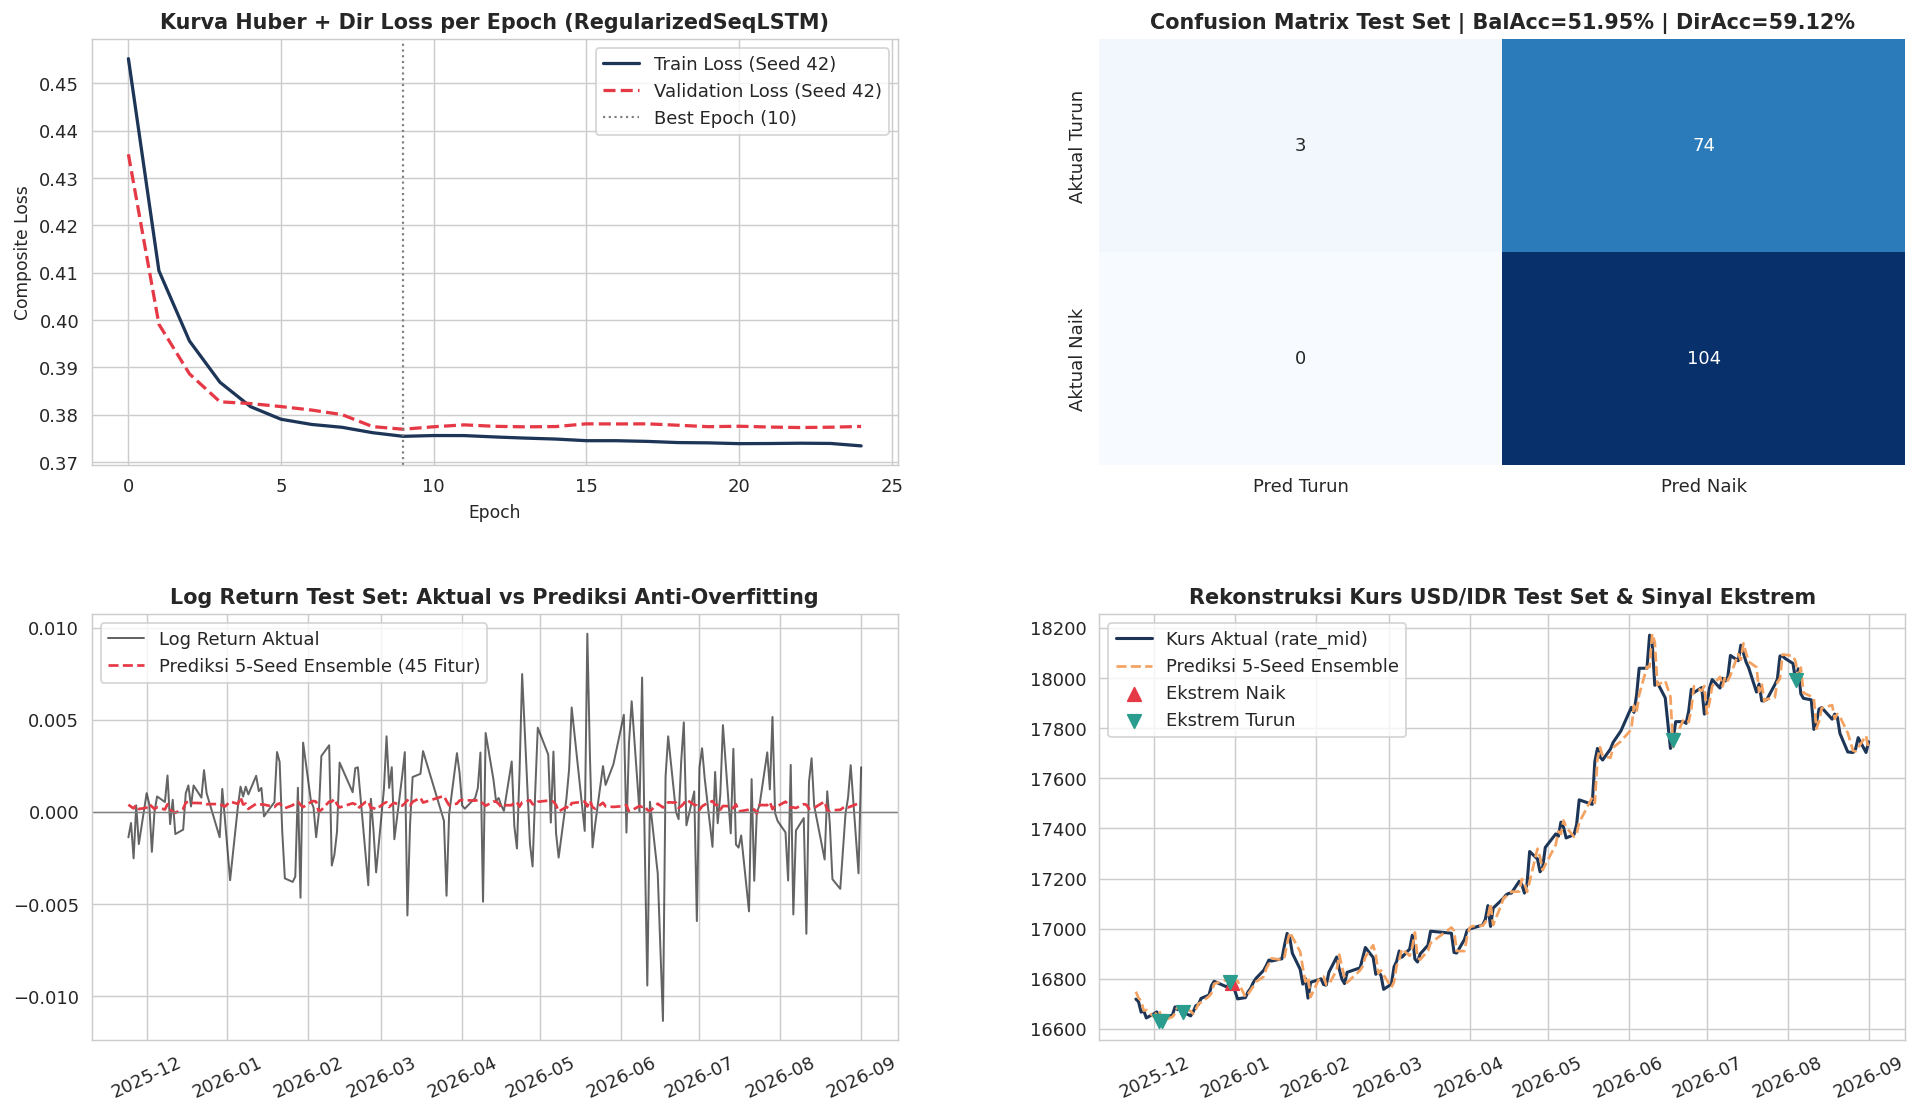

,Tanggal,Kurs Aktual,Kurs Prediksi,LogRet Aktual,LogRet Prediksi,Arah Aktual,Arah Prediksi
171,2026-08-18,17836.0,17892.09,-0.002576,0.000564,Turun,Naik
172,2026-08-19,17856.0,17837.78,0.001121,0.000100,Naik,Naik
173,2026-08-20,17844.0,17856.47,-0.000672,0.000027,Turun,Naik
174,2026-08-21,17779.0,17845.59,-0.003649,0.000089,Turun,Naik
175,2026-08-24,17705.0,17781.12,-0.004171,0.000119,Turun,Naik
176,2026-08-26,17703.0,17710.50,-0.000113,0.000311,Turun,Naik
177,2026-08-27,17717.0,17707.35,0.000791,0.000245,Naik,Naik
178,2026-08-28,17762.0,17722.30,0.002537,0.000299,Naik,Naik
179,2026-08-31,17703.0,17770.21,-0.003327,0.000462,Turun,Naik
180,2026-09-01,17746.0,17711.77,0.002426,0.000495,Naik,Naik


In [14]:
#visualisasi akhir
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# 1. Kurva Composite Loss Train vs Val (Seed 42)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(res_best["tr_hist"], label="Train Loss (Seed 42)", color="#1d3557", lw=1.8)
ax1.plot(res_best["va_hist"], label="Validation Loss (Seed 42)", color="#e63946", linestyle="--", lw=1.8)
ax1.axvline(max(res_best["best_epoch"] - 1, 0), color="gray", linestyle=":", lw=1.2, label=f"Best Epoch ({res_best['best_epoch']})")
ax1.set_title("Kurva Huber + Dir Loss per Epoch (RegularizedSeqLSTM)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Composite Loss")
ax1.legend()

# 2. Confusion Matrix Prediksi Arah (Test Set — 5-Seed Ensemble)
ax2 = fig.add_subplot(gs[0, 1])
cm = confusion_matrix(y_te_dir_true, y_te_dir_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred Turun", "Pred Naik"],
            yticklabels=["Aktual Turun", "Aktual Naik"], ax=ax2)
ax2.set_title(
    f"Confusion Matrix Test Set | BalAcc={eval_summary_df.loc[TEST_ROW_LABEL, 'BalAcc (%)']:.2f}% "
    f"| DirAcc={eval_summary_df.loc[TEST_ROW_LABEL, 'DirAcc (%)']:.2f}%"
)

# 3. Deret Waktu Log Return Aktual vs Prediksi (Test Set)
te_dates = seq_data["dates"][te_m]
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(te_dates, y_te_true, label="Log Return Aktual", color="#222222", alpha=0.7, lw=1.1)
ax3.plot(te_dates, res_best["pred_te"], label="Prediksi 5-Seed Ensemble (45 Fitur)", color="#e63946", linestyle="--", lw=1.5)
ax3.axhline(0, color="gray", lw=0.8)
ax3.set_title("Log Return Test Set: Aktual vs Prediksi Anti-Overfitting")
ax3.tick_params(axis="x", rotation=25)
ax3.legend()

# 4. Rekonstruksi Kurs USD/IDR + Sinyal Sentimen Ekstrem (Test Set)
ax4 = fig.add_subplot(gs[1, 1])
prev_r = seq_data["prev_rate"][te_m]
curr_r = seq_data["curr_rate"][te_m]
pred_r = prev_r * np.exp(res_best["pred_te"])
ax4.plot(te_dates, curr_r, label="Kurs Aktual (rate_mid)", color="#1d3557", lw=1.7)
ax4.plot(te_dates, pred_r, label="Prediksi 5-Seed Ensemble", color="#f4a261", linestyle="--", lw=1.5)

te_align = df_model.loc[df_model[date_col].isin(te_dates)].copy()
ex_up = te_align[te_align["flag_naik_ekstrem"] == 1]
ex_dn = te_align[te_align["flag_turun_ekstrem"] == 1]
ax4.scatter(ex_up[date_col], ex_up["rate_mid"], marker="^", s=55, color="#e63946", zorder=5, label="Ekstrem Naik")
ax4.scatter(ex_dn[date_col], ex_dn["rate_mid"], marker="v", s=55, color="#2a9d8f", zorder=5, label="Ekstrem Turun")
ax4.set_title("Rekonstruksi Kurs USD/IDR Test Set & Sinyal Ekstrem")
ax4.tick_params(axis="x", rotation=25)
ax4.legend()

plt.tight_layout()
plt.show()

pred_test_df = pd.DataFrame({
    "Tanggal": te_dates,
    "Kurs Aktual": np.round(curr_r, 2),
    "Kurs Prediksi": np.round(pred_r, 2),
    "LogRet Aktual": np.round(y_te_true, 6),
    "LogRet Prediksi": np.round(res_best["pred_te"], 6),
    "Arah Aktual": np.where(y_te_dir_true == 1, "Naik", "Turun"),
    "Arah Prediksi": np.where(y_te_dir_pred == 1, "Naik", "Turun"),
})
display(pred_test_df.tail(10))

=== IMPORTANCE PER GRUP (Val) ===


,Fitur,ΔRMSE (×1e-6),ΔRMSE sd (×1e-6),ΔBalAcc (poin),ΔBalAcc sd
0,DeBERTa-Title (4),7.643,3.689,0.161,0.681
1,TS (14),5.080,7.620,-0.662,1.170
2,FinBERT-Sent (5),3.757,2.675,0.062,0.628
3,BERTopic (7),-2.253,7.668,-0.501,1.076
4,Sent×Arah (15),-4.000,7.287,-0.327,0.834


=== IMPORTANCE PER GRUP (Test) ===


,Fitur,ΔRMSE (×1e-6),ΔRMSE sd (×1e-6),ΔBalAcc (poin),ΔBalAcc sd
0,TS (14),7.769,7.289,0.921,1.126
1,Sent×Arah (15),3.238,7.363,1.624,0.621
2,FinBERT-Sent (5),-0.581,2.968,0.560,0.431
3,BERTopic (7),-1.278,4.353,0.252,0.867
4,DeBERTa-Title (4),-4.307,2.550,0.786,0.733


=== TOP-15 FITUR (Val) ===


,Fitur,ΔRMSE (×1e-6),ΔRMSE sd (×1e-6),ΔBalAcc (poin),ΔBalAcc sd
0,ret_lag2,6.898,4.410,0.131,0.748
1,deberta_pca_0,5.850,2.158,0.208,0.451
2,dow_sin,3.275,5.888,-1.200,0.731
3,dist_ma20,2.115,2.856,-0.466,0.460
4,rsi_14,1.996,0.997,0.890,0.312
5,ret_lag1,1.993,2.404,0.992,0.382
6,topic_umap_1,1.885,1.773,0.161,0.633
7,topic_umap_0,1.714,2.499,0.528,0.445
8,dist_ma10,1.416,1.533,0.139,0.530
9,finbert_neu,1.401,1.936,0.159,0.440


=== TOP-15 FITUR (Test) ===


,Fitur,ΔRMSE (×1e-6),ΔRMSE sd (×1e-6),ΔBalAcc (poin),ΔBalAcc sd
0,ret_lag2,6.512,3.719,-0.302,0.604
1,topic_pca_0,3.148,1.847,0.362,0.465
2,finbert_neg,2.816,1.855,0.132,0.623
3,sent_magnitude,2.733,4.506,1.399,0.958
4,topic_pca_3,1.805,3.482,0.442,0.540
5,sent_mag_x_dir,1.725,1.748,0.366,0.555
6,consec_up_days,1.213,1.654,0.249,0.423
7,ret_lag1,1.040,2.313,0.373,0.499
8,deberta_pca_2,0.744,1.602,0.246,0.543
9,flag_naik_ekstrem,0.554,0.827,0.065,0.195


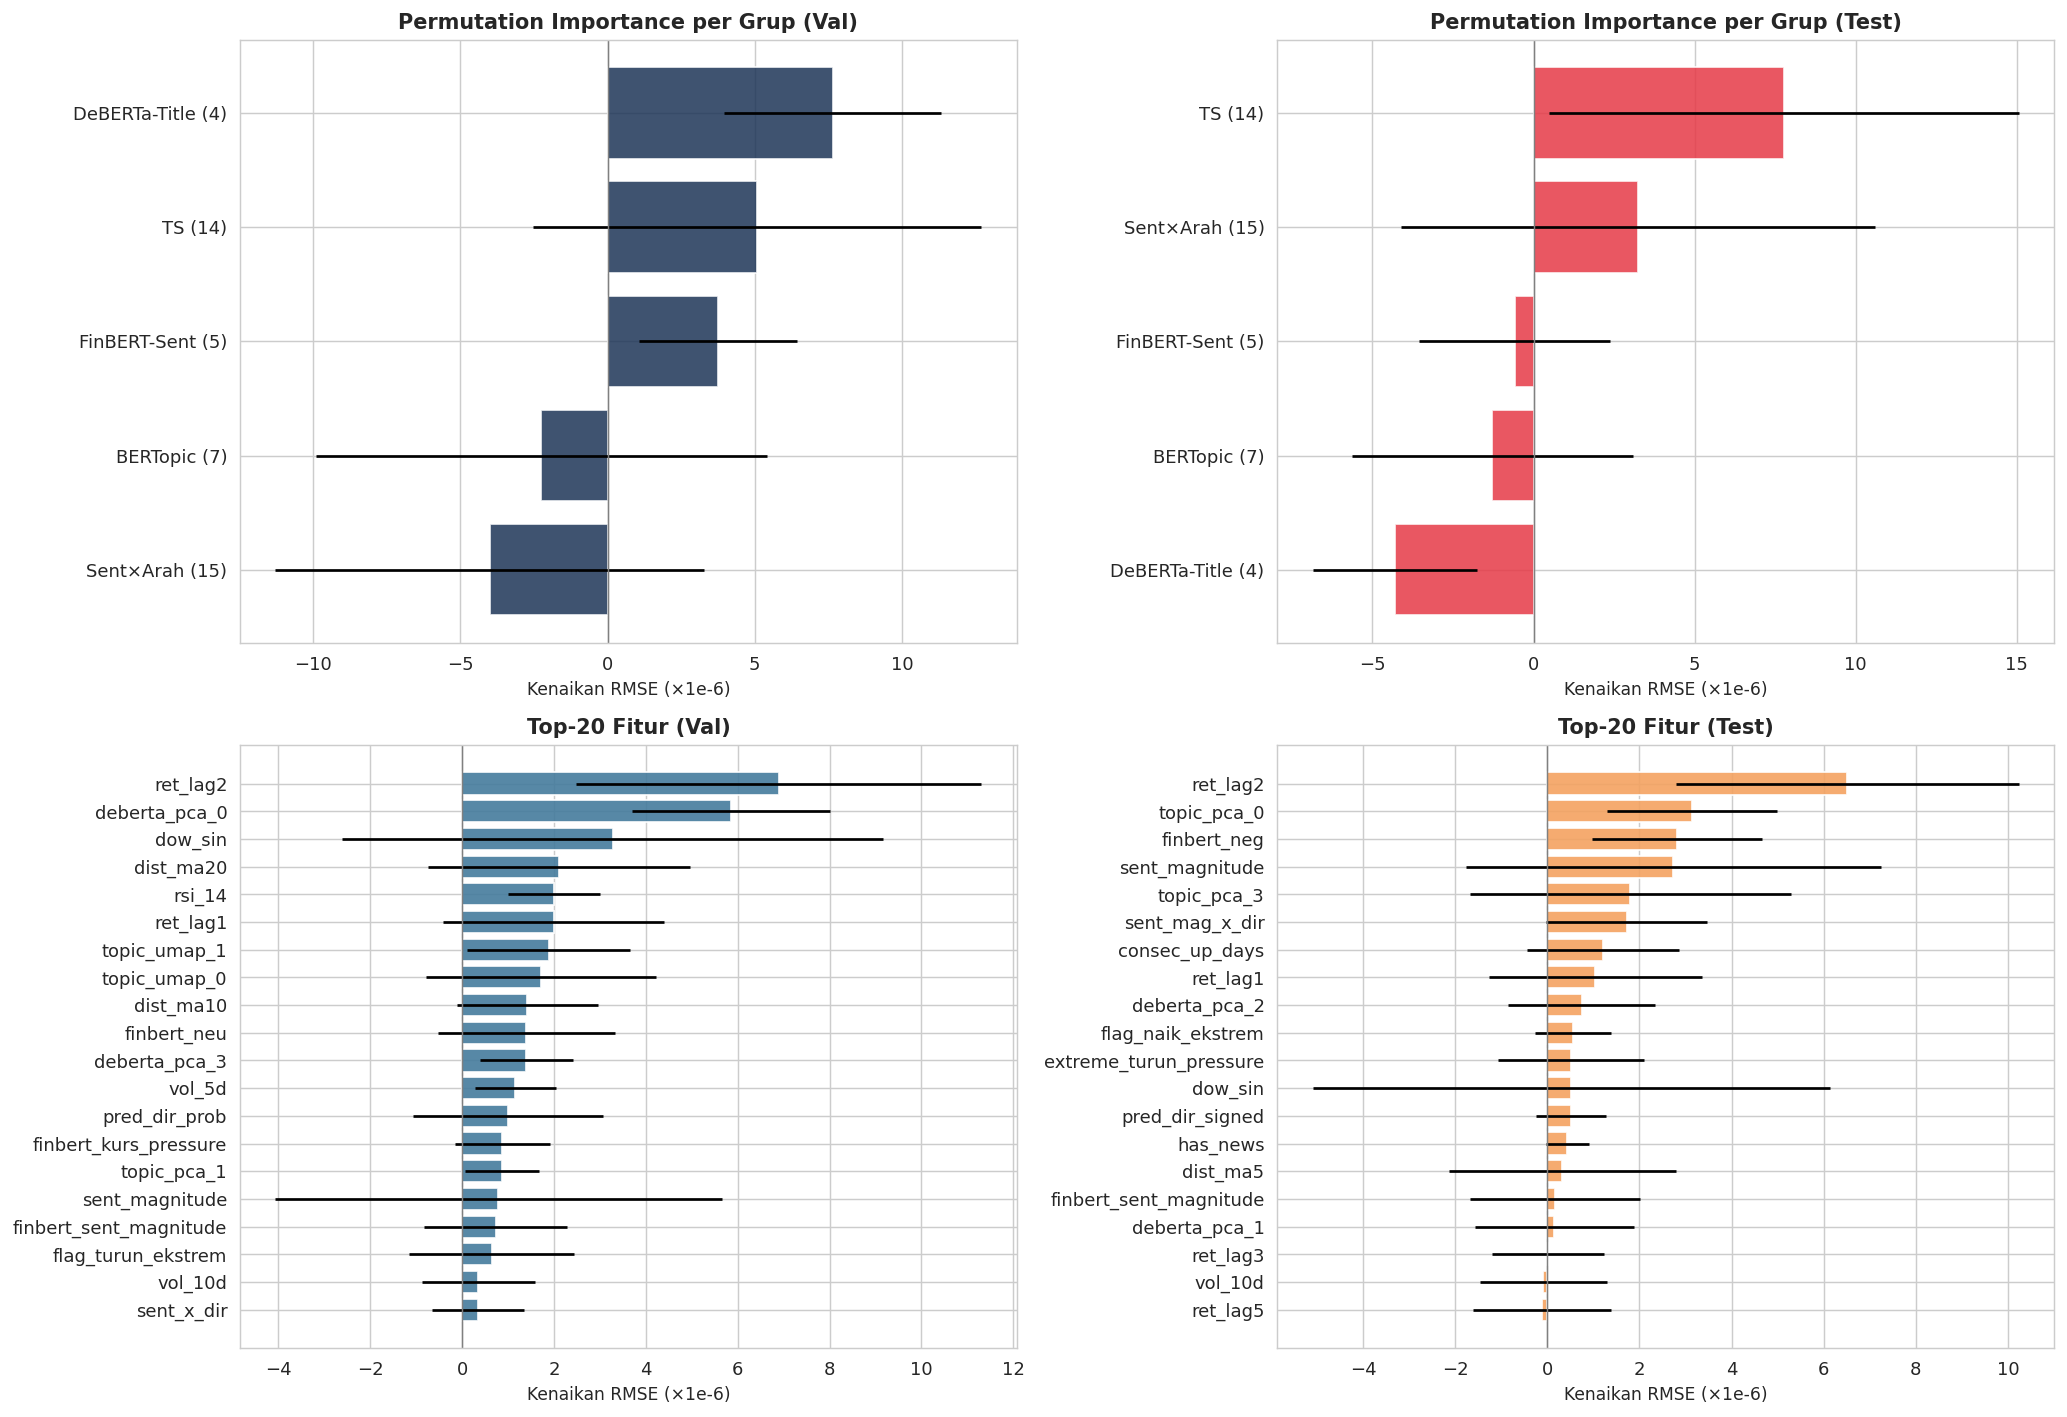

Spearman korelasi importance Val vs Test: rho=-0.079 (p=0.605)
=== STAGE 1 LogReg: Top-15 |Koefisien| ===


,Fitur,Koef,AbsKoef
0,topic_umap_0,-0.2024,0.2024
1,topic_pca_4,-0.1498,0.1498
2,finbert_sent_magnitude,-0.1479,0.1479
3,deberta_pca_7,0.1080,0.1080
4,deberta_pca_3,0.0802,0.0802
5,topic_pca_2,0.0778,0.0778
6,topic_pca_1,0.0766,0.0766
7,deberta_pca_5,-0.0693,0.0693
8,finbert_sent_ratio,0.0532,0.0532
9,deberta_pca_2,0.0518,0.0518


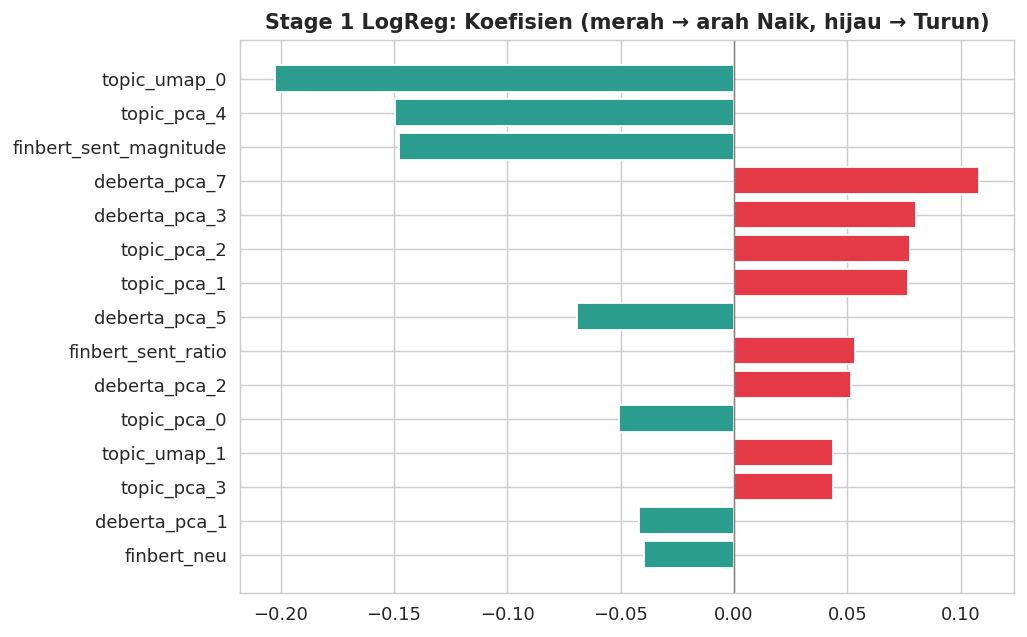

In [18]:
# ===== FEATURE IMPORTANCE: Permutation (per fitur & per grup) + koefisien Stage 1 =====
GROUPS_FI = {
    "TS (14)": GRP_TS,
    "DeBERTa-Title (4)": GRP_DEBERTA_TITLE,
    "FinBERT-Sent (5)": GRP_FINBERT_SENT,
    "Sent×Arah (15)": GRP_SENT_INTER,
    "BERTopic (7)": GRP_BERTOPIC,
}
col_idx = {c: i for i, c in enumerate(BEST_COLS)}

def predict_ens(X):
    Xt = torch.tensor(X, dtype=torch.float32).to(DEVICE)
    preds = []
    for r in res_best["runs"]:
        m = r["model"].eval()
        with torch.no_grad():
            preds.append(m(Xt).cpu().numpy() * seq_data["std_y"] + seq_data["mu_y"])
    return np.mean(preds, axis=0)

def _metrics(y, p):
    return (float(np.sqrt(np.mean((y - p) ** 2))),
            balanced_accuracy_score((y > 0).astype(int), (p > 0).astype(int)) * 100)

def perm_importance(X, y, groups: dict, n_rep=30, seed=SEED):
    rng = np.random.default_rng(seed)
    base_rmse, base_bal = _metrics(y, predict_ens(X))
    rows = []
    for name, cols in groups.items():
        idx = [col_idx[c] for c in cols]
        d_rmse, d_bal = [], []
        for _ in range(n_rep):
            perm = rng.permutation(len(X))      # acak antar-sampel, seluruh window fitur ikut
            Xp = X.copy()
            Xp[:, :, idx] = X[perm][:, :, idx]
            r, b = _metrics(y, predict_ens(Xp))
            d_rmse.append(r - base_rmse)        # >0 => fitur penting (error naik)
            d_bal.append(base_bal - b)          # >0 => fitur penting (BalAcc turun)
        rows.append({"Fitur": name,
                     "ΔRMSE (×1e-6)": np.mean(d_rmse) * 1e6,
                     "ΔRMSE sd (×1e-6)": np.std(d_rmse) * 1e6,
                     "ΔBalAcc (poin)": np.mean(d_bal),
                     "ΔBalAcc sd": np.std(d_bal)})
    return (pd.DataFrame(rows).sort_values("ΔRMSE (×1e-6)", ascending=False)
            .reset_index(drop=True))

fi = {}
for split_name, m in [("Val", va_m), ("Test", te_m)]:
    X_s, y_s = seq_data["X"][m], seq_data["y_raw"][m]
    fi[split_name] = {
        "feat": perm_importance(X_s, y_s, {c: [c] for c in BEST_COLS}),
        "group": perm_importance(X_s, y_s, GROUPS_FI),
    }

print("=== IMPORTANCE PER GRUP (Val) ===");  display(fi["Val"]["group"].round(3))
print("=== IMPORTANCE PER GRUP (Test) ==="); display(fi["Test"]["group"].round(3))
print("=== TOP-15 FITUR (Val) ===");  display(fi["Val"]["feat"].head(15).round(3))
print("=== TOP-15 FITUR (Test) ==="); display(fi["Test"]["feat"].head(15).round(3))

# Plot
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for j, sp in enumerate(["Val", "Test"]):
    g = fi[sp]["group"].iloc[::-1]
    axes[0, j].barh(g["Fitur"], g["ΔRMSE (×1e-6)"], xerr=g["ΔRMSE sd (×1e-6)"],
                    color="#1d3557" if sp == "Val" else "#e63946", alpha=0.85)
    axes[0, j].axvline(0, color="gray", lw=0.8)
    axes[0, j].set_title(f"Permutation Importance per Grup ({sp})")
    axes[0, j].set_xlabel("Kenaikan RMSE (×1e-6)")

    f = fi[sp]["feat"].head(20).iloc[::-1]
    axes[1, j].barh(f["Fitur"], f["ΔRMSE (×1e-6)"], xerr=f["ΔRMSE sd (×1e-6)"],
                    color="#457b9d" if sp == "Val" else "#f4a261", alpha=0.9)
    axes[1, j].axvline(0, color="gray", lw=0.8)
    axes[1, j].set_title(f"Top-20 Fitur ({sp})")
    axes[1, j].set_xlabel("Kenaikan RMSE (×1e-6)")
plt.tight_layout(); plt.show()

# Konsistensi peringkat Val vs Test (stabilitas importance)
mrg = fi["Val"]["feat"].merge(fi["Test"]["feat"], on="Fitur", suffixes=("_val", "_test"))
rho, pv = stats.spearmanr(mrg["ΔRMSE (×1e-6)_val"], mrg["ΔRMSE (×1e-6)_test"])
print(f"Spearman korelasi importance Val vs Test: rho={rho:+.3f} (p={pv:.3f})")

# Stage 1: koefisien LogReg (fitur sudah di-standardisasi)
s1_coef = (pd.DataFrame({"Fitur": stage1_cols, "Koef": final_s1.coef_[0]})
           .assign(AbsKoef=lambda d: d["Koef"].abs())
           .sort_values("AbsKoef", ascending=False).reset_index(drop=True))
print("=== STAGE 1 LogReg: Top-15 |Koefisien| ===")
display(s1_coef.head(15).round(4))
plt.figure(figsize=(8, 5))
t = s1_coef.head(15).iloc[::-1]
plt.barh(t["Fitur"], t["Koef"], color=np.where(t["Koef"] > 0, "#e63946", "#2a9d8f"))
plt.axvline(0, color="gray", lw=0.8)
plt.title("Stage 1 LogReg: Koefisien (merah → arah Naik, hijau → Turun)")
plt.tight_layout(); plt.show()

# Ablation Study

,Tipe,#Fitur,Val BalAcc,Val RMSE,Test BalAcc,Test BalAcc±sd,Test DirAcc,Test F1-Macro,Test RMSE,Test R2,Δ Test BalAcc vs Full,Δ Val BalAcc vs Full
Skenario,,,,,,,,,,,,
Full (45 fitur),full,45,49.18,0.003381,51.49,1.48,58.01,42.95,0.002877,0.0045,0.00,0.00
– TS (14),drop-one,31,50.82,0.003382,52.60,0.72,59.67,41.95,0.002892,-0.0056,1.11,1.64
– DeBERTa-Title (4),drop-one,41,52.08,0.003368,57.34,1.59,62.98,52.82,0.002871,0.0088,5.85,2.90
– FinBERT-Sent (5),drop-one,40,50.97,0.003380,54.74,0.70,60.77,48.63,0.002886,-0.0015,3.25,1.79
– Sent×Arah (15),drop-one,30,50.97,0.003385,51.83,2.21,58.01,44.62,0.002894,-0.0075,0.34,1.79
– BERTopic (7),drop-one,38,53.42,0.003365,55.78,1.37,60.22,53.46,0.002881,0.0022,4.29,4.24
Only TS (14),only-one,14,53.87,0.003377,49.71,0.84,56.35,40.23,0.002892,-0.0055,-1.78,4.69
Only DeBERTa-Title (4),only-one,4,50.07,0.003381,49.52,1.42,56.91,36.27,0.002905,-0.0147,-1.97,0.89
Only FinBERT-Sent (5),only-one,5,51.41,0.003387,50.99,2.18,58.01,40.09,0.002886,-0.0015,-0.50,2.23


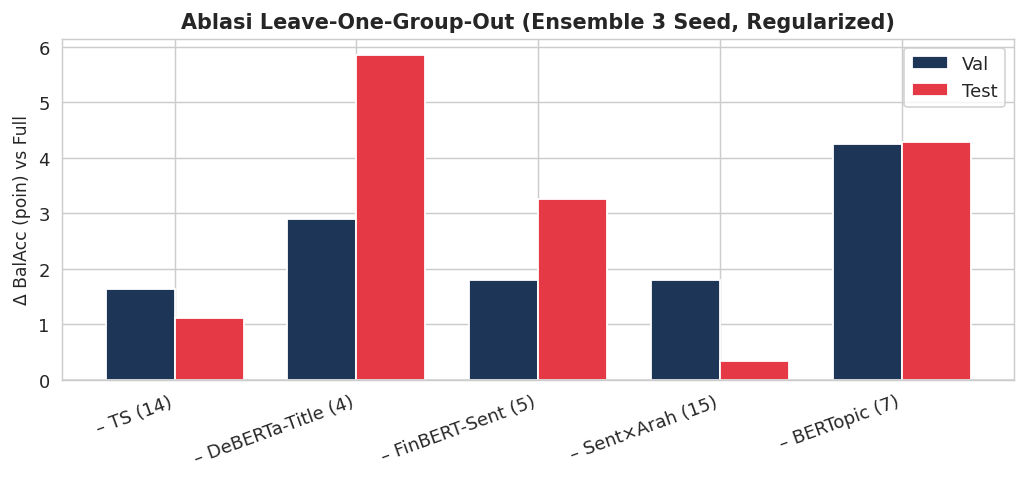

In [13]:
GROUPS = {
    "TS (14)": GRP_TS,
    "DeBERTa-Title (4)": GRP_DEBERTA_TITLE,
    "FinBERT-Sent (5)": GRP_FINBERT_SENT,
    "Sent×Arah (15)": GRP_SENT_INTER,
    "BERTopic (7)": GRP_BERTOPIC,
}
ABL_SEEDS = (42, 7, 123)

def run_cfg(cols, seeds=ABL_SEEDS):
    sd = build_sequences(df_model, cols, BEST_SEQ_LEN)
    s_ = sd["split"]
    tr, va, te = s_ == "train", s_ == "val", s_ == "test"
    yv, yt = sd["y_raw"][va], sd["y_raw"][te]
    p_va_seeds, p_te_seeds = [], []
    va_bals, te_bals = [], []
    for s in seeds:
        m = RegularizedSeqLSTM(
            input_dim=len(cols),
            proj_dim=min(BEST_CFG["proj_dim"], max(8, len(cols))),
            hidden_dim=BEST_CFG["hidden_dim"],
            input_dropout=BEST_CFG["input_dropout"],
            dropout=BEST_CFG["dropout"],
            noise_std=BEST_CFG["noise_std"],
            bidirectional=BEST_CFG["bidirectional"],
        )
        r = train_pytorch_regressor(
            m, sd["X"][tr], sd["y_s"][tr], sd["X"][va], sd["y_s"][va], sd["X"][te],
            sd["mu_y"], sd["std_y"], lr=BEST_CFG["lr"], weight_decay=BEST_CFG["weight_decay"],
            dir_lambda=BEST_CFG["dir_lambda"], batch_size=BEST_CFG["batch_size"],
            epochs=BEST_CFG["epochs"], patience=BEST_CFG["patience"], min_epochs=BEST_CFG["min_epochs"], seed=s,
        )
        p_va_seeds.append(r["pred_va"])
        p_te_seeds.append(r["pred_te"])
        va_bals.append(eval_reg("", yv, r["pred_va"])["BalAcc (%)"])
        te_bals.append(eval_reg("", yt, r["pred_te"])["BalAcc (%)"])

    ens_va_m = eval_reg("", yv, np.mean(p_va_seeds, axis=0))
    ens_te_m = eval_reg("", yt, np.mean(p_te_seeds, axis=0))
    return ens_va_m, ens_te_m, float(np.std(te_bals))

records = []
def add(name, cols, kind):
    v, t, t_sd = run_cfg(cols)
    records.append({
        "Skenario": name, "Tipe": kind, "#Fitur": len(cols),
        "Val BalAcc": v["BalAcc (%)"], "Val RMSE": v["RMSE"],
        "Test BalAcc": t["BalAcc (%)"], "Test BalAcc±sd": round(t_sd, 2),
        "Test DirAcc": t["DirAcc (%)"], "Test F1-Macro": t["F1-Macro (%)"],
        "Test RMSE": t["RMSE"], "Test R2": t["R2"],
    })

add("Full (45 fitur)", BEST_COLS, "full")
for g, cols in GROUPS.items():
    keep = [c for c in BEST_COLS if c not in cols]
    add(f"– {g}", keep, "drop-one")
for g, cols in GROUPS.items():
    add(f"Only {g}", cols, "only-one")
for g, cols in GROUPS.items():
    if g.startswith("TS"):
        continue
    add(f"TS + {g}", GRP_TS + cols, "TS+one")

abl_df = pd.DataFrame(records).set_index("Skenario")
full = abl_df.loc["Full (45 fitur)"]
abl_df["Δ Test BalAcc vs Full"] = (abl_df["Test BalAcc"] - full["Test BalAcc"]).round(2)
abl_df["Δ Val BalAcc vs Full"] = (abl_df["Val BalAcc"] - full["Val BalAcc"]).round(2)
display(abl_df.round(9))

d = abl_df[abl_df["Tipe"] == "drop-one"]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(d)); w = 0.38
ax.bar(x - w/2, d["Δ Val BalAcc vs Full"], w, label="Val", color="#1d3557")
ax.bar(x + w/2, d["Δ Test BalAcc vs Full"], w, label="Test", color="#e63946")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=20, ha="right")
ax.set_ylabel("Δ BalAcc (poin) vs Full")
ax.set_title("Ablasi Leave-One-Group-Out (Ensemble 3 Seed, Regularized)")
ax.legend(); plt.tight_layout(); plt.show()

## 12. Error Analysis (Test Set & Validation Set)

Bagian ini membedah secara sistematis kapan dan mengapa `RegularizedSeqLSTM` (5-Seed Ensemble, 45 fitur) melakukan kesalahan pada **Test Set** (dengan pembanding dari **Validation Set** & **Train Set** tanpa kebocoran data):
1. **Ringkasan Bias Prediksi Arah & Kalibrasi Distribusi** (*prediction shrinkage* vs `mu_train_raw`, korelasi Pearson/Spearman, sensitivitas threshold berbasis Train/Val).
2. **Breakdown Error per Rezim Pasar & Berita**: kuartil magnitudo pergerakan (`|log_ret|`), rezim volatilitas (`vol_10d`, split berdasarkan median Train), keberadaan berita (`has_news`), tier intensitas sentimen FinBERT (Q70/Q90 Train), kesepakatan Stage 1 vs Stage 2, tren per bulan, dan efek hari perdagangan (`Senin–Jumat`).
3. **Inspeksi Kasus Ekstrem**: 10 error regresi terbesar (`|err|`) dan 10 kesalahan arah dengan keyakinan tertinggi beserta judul beritanya.
4. **Visualisasi Diagnostik Error (2×2)**.


=== 1. RINGKASAN BIAS PREDIKSI & KORELASI (TEST SET) ===
Sampel Test : 181 | TP=104, TN=3, FP(Salah Naik)=74, FN(Salah Turun)=0
Proporsi Naik Aktual vs Prediksi : 57.46% vs 98.34%
Mean Return Aktual vs Prediksi   : +0.000322 vs +0.000367 (mu_train=+0.000162)
Std Return Aktual vs Prediksi    : 0.002892 vs 0.000180 (rasio shrinkage=0.062x)
Korelasi Pearson  : r=+0.0567 (p=0.4487) | Spearman rho=+0.0484 (p=0.5180)
MAE Kurs (IDR)    : Rp 37.45 | Median Abs Err: Rp 28.54 | Max: Rp 206.38

--- Diagnostik Sensitivitas Threshold Keputusan Arah (Indikasi Calibration Bias) ---


,Nilai,Val Pred Naik (%),Val BalAcc (%),Test Pred Naik (%),Test DirAcc (%),Test BalAcc (%),Test F1-Macro (%)
Threshold,,,,,,,
Threshold 0.0 (Default),0.000000,97.2,49.63,98.3,59.12,51.95,40.63
Mean Train (mu_train_raw),0.000162,79.4,46.35,85.1,60.22,55.10,51.43
Median Prediksi Val,0.000298,50.0,48.88,65.2,55.80,53.62,53.41
Median Prediksi Train,0.000278,52.2,47.62,68.5,54.70,51.98,51.42



=== 2A. ERROR BERDASARKAN KUARTIL MAGNITUDO |log_ret| (TEST SET) ===


,move_quartile,N,Naik Akt (%),Naik Pred (%),DirAcc (%),BalAcc (%),RMSE,MAE,MAE (IDR),Bias (y-ŷ)
0,Q1 (Tenang),46,50.0,95.7,54.35,54.35,0.000615,0.000492,8.52,-0.000297
1,Q2 (Kecil),45,57.8,97.8,60.00,52.63,0.001237,0.001142,19.65,-0.000206
2,Q3 (Sedang),45,71.1,100.0,71.11,50.00,0.002299,0.002239,38.77,0.000687
3,Q4 (Shock),45,51.1,100.0,51.11,50.00,0.005113,0.004763,83.50,-0.000361


=== 2B. ERROR BERDASARKAN REZIM VOLATILITAS, BERITA, SENTIMEN, & KESEPAKATAN STAGE 1-2 ===


,N,Naik Akt (%),Naik Pred (%),DirAcc (%),BalAcc (%),RMSE,MAE,MAE (IDR),Bias (y-ŷ)
Segmen,,,,,,,,,
Volatilitas Rendah (<Med Tr),104,58.7,98.1,60.58,52.33,0.002789,0.002101,36.19,-0.000120
Volatilitas Tinggi (>=Med Tr),77,55.8,98.7,57.14,51.47,0.002997,0.002214,39.15,0.000055
Ada Berita,177,58.2,98.3,59.89,52.03,0.002883,0.002149,37.46,0.000003
Tanpa Berita,4,25.0,100.0,25.00,50.00,0.002707,0.002176,36.92,-0.002176
Ekstrem (>=Q90),7,28.6,85.7,42.86,60.00,0.002012,0.001580,27.40,-0.000866
Normal (<Q70),141,59.6,99.3,60.28,50.88,0.002990,0.002188,38.11,-0.000025
Tinggi (Q70-Q90),33,54.5,97.0,57.58,53.33,0.002533,0.002105,36.76,0.000042
Stage1 & Stage2 Sepakat,110,60.9,99.1,61.82,51.16,0.002706,0.002064,35.85,0.000110
Stage1 vs Stage2 Berbeda,71,52.1,97.2,54.93,52.94,0.003129,0.002282,39.92,-0.000287


... (3 outputs left out)


=== 3A. TOP-10 ERROR REGRESI TERBESAR (TEST SET) ===


,Tanggal_dt,curr_rate,pred_rate,err_idr,y_true,y_pred,dir_correct,pred_dir_prob,kurs_pressure,title_clean
128,2026-06-17,17719.0,17925.379517,-206.379517,-0.011336,0.000244,0,0.496103,-0.228948,Trump turns his attention to Ukraine ahead of ...
125,2026-06-11,17971.0,18142.996057,-171.996057,-0.009415,0.000110,0,0.549523,-0.187879,Trump keeps saying an Iran deal is close. Mark...
111,2026-05-19,17666.0,17501.214214,164.785786,0.009670,0.000298,1,0.456608,0.426088,Lululemon takes battle with Chip Wilson public...
123,2026-06-09,18171.0,18043.965311,127.034689,0.007291,0.000275,1,0.557317,-0.181196,Airline profits set to halve this year as fuel...
167,2026-08-11,17795.0,17920.059619,-125.059619,-0.006609,0.000394,0,0.495708,-0.357948,Three reasons Goldman’s co-head of global bank...
97,2026-04-24,17308.0,17187.996409,120.003591,0.007481,0.000523,1,0.539485,0.191690,How the Iran war has stoked competition betwee...
137,2026-06-30,17856.0,17968.216012,-112.216012,-0.005919,0.000346,0,0.351767,-0.825569,"AeroVironment soars 28% on earnings beat, back..."
71,2026-03-11,16879.0,16984.865972,-105.865972,-0.005613,0.000640,0,0.522900,0.213708,"China’s nudge, U.S. waiver and Iran tensions t..."
121,2026-06-05,18039.0,17932.504829,106.495171,0.006005,0.000084,1,0.459733,0.343777,Bitcoin is weathering its ugliest week in mont...
164,2026-08-06,17937.0,18041.465920,-104.465920,-0.005560,0.000247,0,0.328277,-0.184426,CNBC Daily Open: A super Thursday of earnings ...


=== 3B. TOP-10 SALAH ARAH DENGAN MAGNITUDO PREDIKSI TERTINGGI (FALSE CONFIDENCE) ===


,Tanggal_dt,curr_rate,pred_rate,err_idr,y_true,y_pred,dir_correct,pred_dir_prob,kurs_pressure,title_clean
76,2026-03-25,16982.0,17004.811500,-22.811500,-0.000471,0.000871,0,0.568729,0.047069,Britain responds to Iran war energy shock by r...
53,2026-02-11,16799.0,16849.971215,-50.971215,-0.002319,0.000711,0,0.598115,0.000000,
135,2026-06-26,17942.0,17966.973413,-24.973413,-0.000724,0.000667,0,0.598115,0.000000,
71,2026-03-11,16879.0,16984.865972,-105.865972,-0.005613,0.000640,0,0.522900,0.213708,"China’s nudge, U.S. waiver and Iran tensions t..."
98,2026-04-27,17278.0,17318.885836,-40.885836,-0.001735,0.000629,0,0.637009,0.124298,"Iran war, U.S. court’s tariff ruling delays In..."
77,2026-03-26,16905.0,16992.089670,-87.089670,-0.004545,0.000594,0,0.562547,0.243715,It’s not just oil and gas. The Strait of Hormu...
141,2026-07-06,17960.0,18004.645893,-44.645893,-0.001891,0.000591,0,0.525169,-0.068333,Pope Leo urges U.S. to welcome immigrants in J...
103,2026-05-05,17368.0,17388.165435,-20.165435,-0.000576,0.000585,0,0.478538,0.103886,"Treasury yields jump as oil turns higher, 30-y..."
60,2026-02-24,16818.0,16894.806600,-76.806600,-0.003976,0.000581,0,0.581061,0.388664,Oil edges lower on U.S. tariff uncertainty and...
110,2026-05-18,17496.0,17523.913024,-27.913024,-0.001028,0.000566,0,0.557669,0.112083,"30-year Treasury yield tops 5.1%, highest in n..."


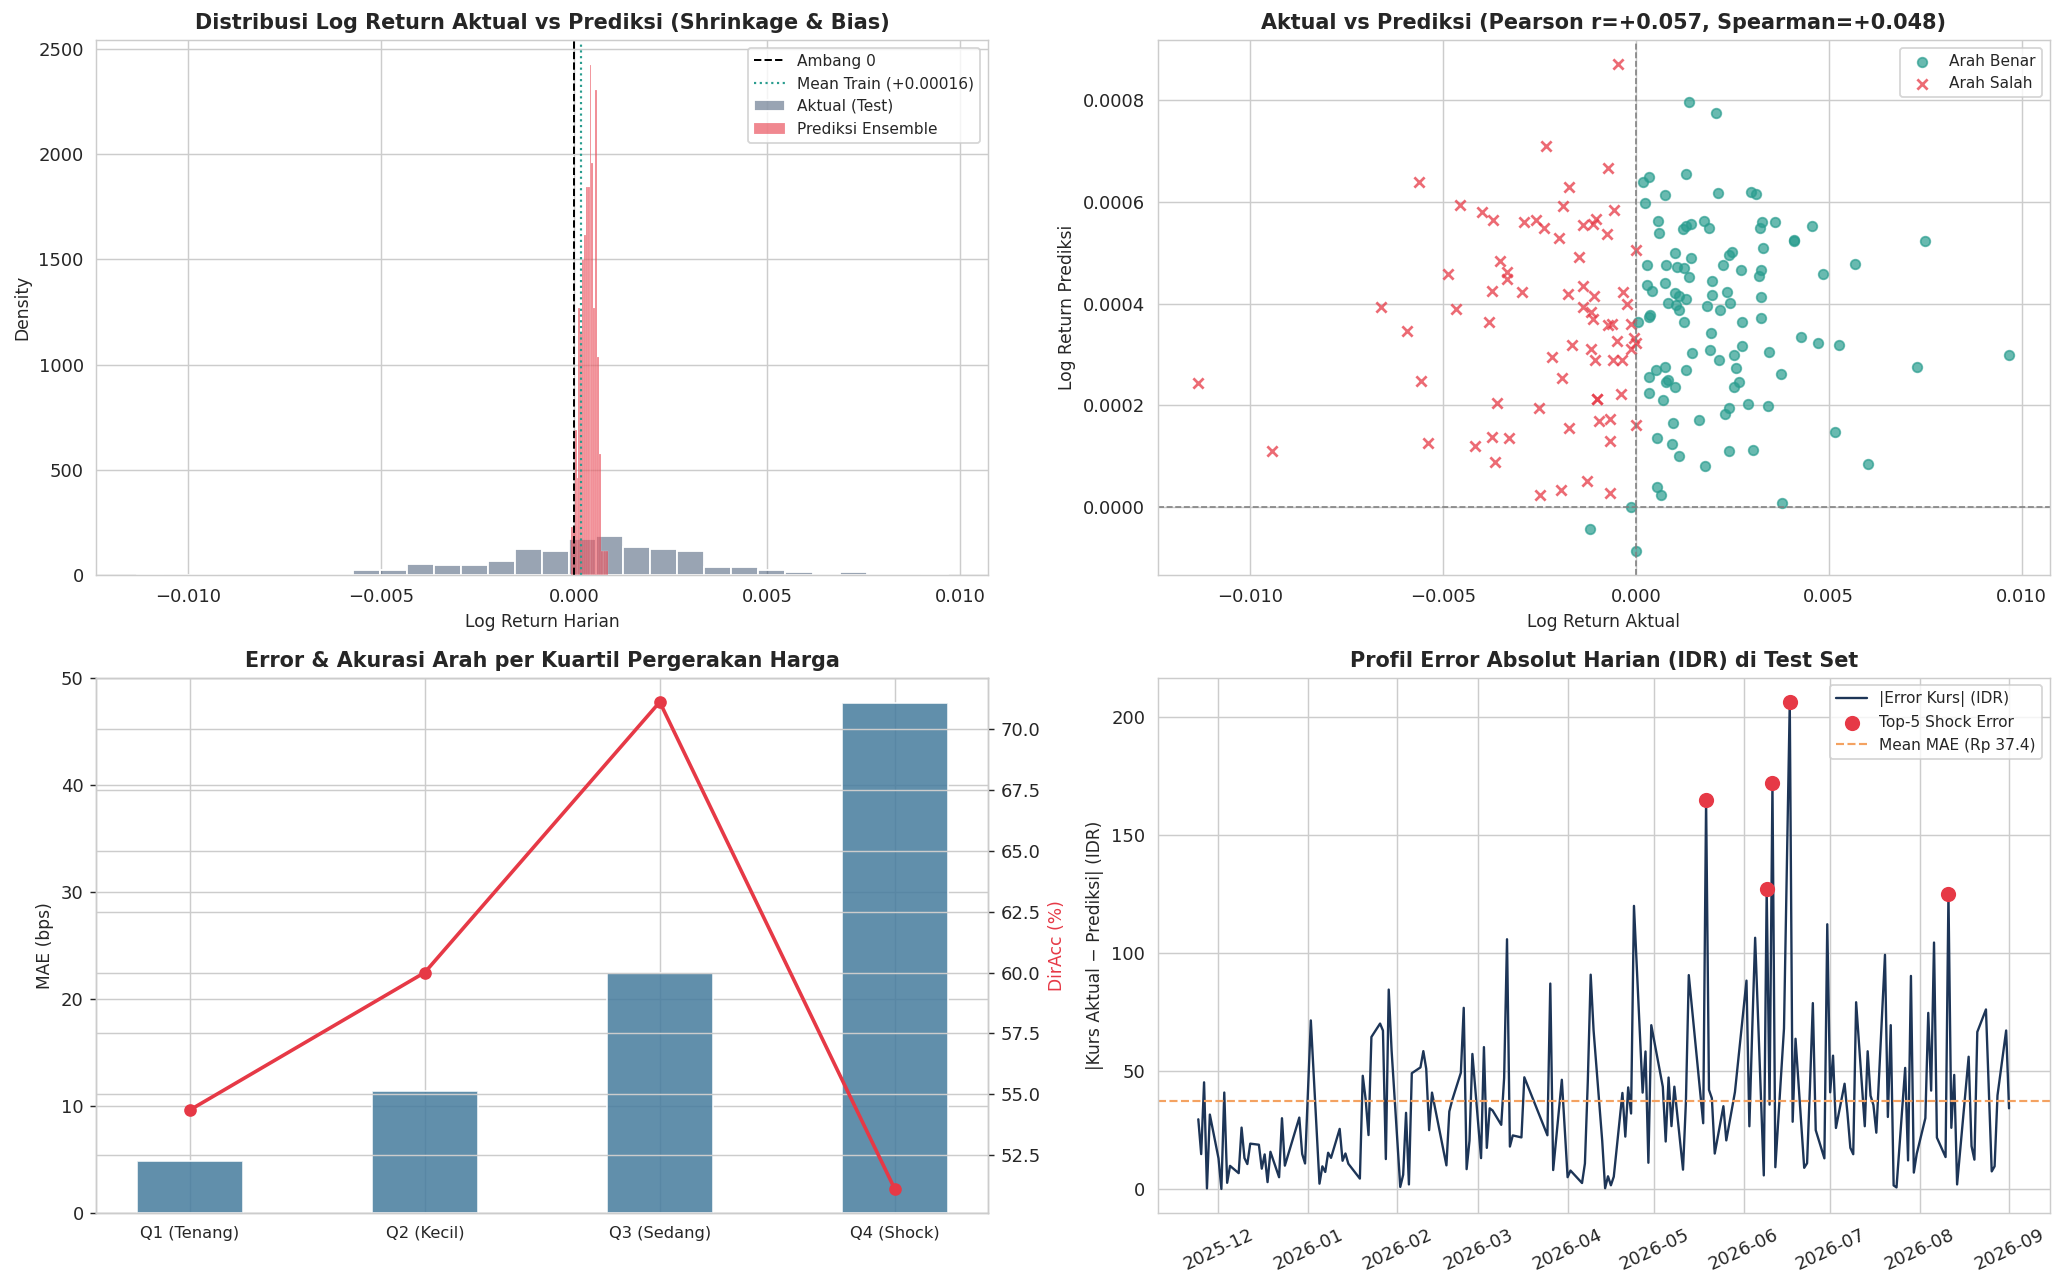

In [17]:
# Bikin tabel analisis error buat train/val/test
def build_eval_frame(split_name: str, preds: np.ndarray) -> pd.DataFrame:
    mask = seq_data["split"] == split_name
    sub = pd.DataFrame({
        date_col: seq_data["dates"][mask],
        "y_true": seq_data["y_raw"][mask],
        "y_pred": preds,
        "prev_rate": seq_data["prev_rate"][mask],
        "curr_rate": seq_data["curr_rate"][mask],
    })
    # kolom tambahan (berita, sentimen, volatilitas) diambil dari df_model lewat tanggal
    meta_cols = [
        date_col, "title_clean", "has_news", "news_count",
        "kurs_pressure", "sent_magnitude", "sent_ratio",
        "pred_dir_prob", "pred_dir_signed", "bt_topic",
        "vol_5d", "vol_10d", "spread_lag1",
        "flag_naik_ekstrem", "flag_turun_ekstrem",
    ]
    sub = sub.merge(df_model[meta_cols], on=date_col, how="left")

    # error dalam skala log return
    sub["err"] = sub["y_true"] - sub["y_pred"]
    sub["abs_err"] = sub["err"].abs()
    sub["sq_err"] = sub["err"] ** 2

    # arah: 1 = naik, 0 = turun
    sub["dir_true"] = (sub["y_true"] > 0).astype(int)
    sub["dir_pred"] = (sub["y_pred"] > 0).astype(int)
    sub["dir_correct"] = (sub["dir_true"] == sub["dir_pred"]).astype(int)

    # balikin prediksi return jadi kurs, biar errornya bisa dibaca dalam rupiah
    sub["pred_rate"] = sub["prev_rate"] * np.exp(sub["y_pred"])
    sub["err_idr"] = sub["curr_rate"] - sub["pred_rate"]
    sub["abs_err_idr"] = sub["err_idr"].abs()
    sub["abs_ret"] = sub["y_true"].abs()

    # cek apakah tebakan arah Stage 1 sama dengan Stage 2
    sub["s1_dir_pred"] = (sub["pred_dir_prob"] >= 0.5).astype(int)
    sub["s1_agree_s2"] = (sub["s1_dir_pred"] == sub["dir_pred"]).astype(int)

    # label waktu buat analisis per bulan dan per hari
    sub["month"] = sub[date_col].dt.to_period("M").astype(str)
    dow_names = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat", 5: "Sabtu", 6: "Minggu"}
    sub["hari"] = sub[date_col].dt.dayofweek.map(dow_names)
    return sub

err_tr_df = build_eval_frame("train", res_best["pred_tr"])
err_va_df = build_eval_frame("val", res_best["pred_va"])
err_te_df = build_eval_frame("test", res_best["pred_te"])

# 1. Gambaran umum: model cenderung bias ke arah mana, korelasinya sekuat apa
tp = int(((err_te_df["dir_true"] == 1) & (err_te_df["dir_pred"] == 1)).sum())
tn = int(((err_te_df["dir_true"] == 0) & (err_te_df["dir_pred"] == 0)).sum())
fp = int(((err_te_df["dir_true"] == 0) & (err_te_df["dir_pred"] == 1)).sum())
fn = int(((err_te_df["dir_true"] == 1) & (err_te_df["dir_pred"] == 0)).sum())

r_pear, p_pear = stats.pearsonr(err_te_df["y_true"], err_te_df["y_pred"])
r_spear, p_spear = stats.spearmanr(err_te_df["y_true"], err_te_df["y_pred"])
# rasio < 1 artinya prediksi "dikecilkan" dibanding variasi aslinya (shrinkage)
std_ratio = float(err_te_df["y_pred"].std() / (err_te_df["y_true"].std() + 1e-12))

print("=== 1. RINGKASAN BIAS PREDIKSI & KORELASI (TEST SET) ===")
print(f"Sampel Test : {len(err_te_df)} | TP={tp}, TN={tn}, FP(Salah Naik)={fp}, FN(Salah Turun)={fn}")
print(f"Proporsi Naik Aktual vs Prediksi : {err_te_df['dir_true'].mean()*100:.2f}% vs {err_te_df['dir_pred'].mean()*100:.2f}%")
print(f"Mean Return Aktual vs Prediksi   : {err_te_df['y_true'].mean():+.6f} vs {err_te_df['y_pred'].mean():+.6f} (mu_train={mu_train_raw:+.6f})")
print(f"Std Return Aktual vs Prediksi    : {err_te_df['y_true'].std():.6f} vs {err_te_df['y_pred'].std():.6f} (rasio shrinkage={std_ratio:.3f}x)")
print(f"Korelasi Pearson  : r={r_pear:+.4f} (p={p_pear:.4f}) | Spearman rho={r_spear:+.4f} (p={p_spear:.4f})")
print(f"MAE Kurs (IDR)    : Rp {err_te_df['abs_err_idr'].mean():.2f} | Median Abs Err: Rp {err_te_df['abs_err_idr'].median():.2f} | Max: Rp {err_te_df['abs_err_idr'].max():.2f}")

# Cek apakah threshold arah = 0 sudah pas, atau model sebenarnya miring ke satu sisi.
# Ini cuma buat diagnosis, bukan buat milih model.
thresh_candidates = {
    "Threshold 0.0 (Default)": 0.0,
    "Mean Train (mu_train_raw)": mu_train_raw,
    "Median Prediksi Val": float(np.median(res_best["pred_va"])),
    "Median Prediksi Train": float(np.median(res_best["pred_tr"])),
}
thresh_rows = []
for tname, th in thresh_candidates.items():
    va_dp = (err_va_df["y_pred"].values > th).astype(int)
    te_dp = (err_te_df["y_pred"].values > th).astype(int)
    thresh_rows.append({
        "Threshold": tname,
        "Nilai": round(th, 6),
        "Val Pred Naik (%)": round(va_dp.mean() * 100, 1),
        "Val BalAcc (%)": round(balanced_accuracy_score(err_va_df["dir_true"], va_dp) * 100, 2),
        "Test Pred Naik (%)": round(te_dp.mean() * 100, 1),
        "Test DirAcc (%)": round(accuracy_score(err_te_df["dir_true"], te_dp) * 100, 2),
        "Test BalAcc (%)": round(balanced_accuracy_score(err_te_df["dir_true"], te_dp) * 100, 2),
        "Test F1-Macro (%)": round(f1_score(err_te_df["dir_true"], te_dp, average="macro") * 100, 2),
    })
print("\n--- Diagnostik Sensitivitas Threshold Keputusan Arah (Indikasi Calibration Bias) ---")
display(pd.DataFrame(thresh_rows).set_index("Threshold"))

# Helper: hitung metrik error per kelompok (kuartil, bulan, hari, dll.)
def summarize_segments(df_seg: pd.DataFrame, col: str) -> pd.DataFrame:
    rows = []
    for key, g in df_seg.groupby(col, observed=False):
        n = len(g)
        if n == 0:
            continue
        # BalAcc cuma bisa dihitung kalau di segmen itu ada kedua kelas (naik dan turun)
        bal = balanced_accuracy_score(g["dir_true"], g["dir_pred"]) * 100 if g["dir_true"].nunique() > 1 else np.nan
        rows.append({
            col: str(key),
            "N": n,
            "Naik Akt (%)": round(g["dir_true"].mean() * 100, 1),
            "Naik Pred (%)": round(g["dir_pred"].mean() * 100, 1),
            "DirAcc (%)": round(g["dir_correct"].mean() * 100, 2),
            "BalAcc (%)": round(bal, 2) if not np.isnan(bal) else np.nan,
            "RMSE": round(float(np.sqrt(g["sq_err"].mean())), 6),
            "MAE": round(float(g["abs_err"].mean()), 6),
            "MAE (IDR)": round(float(g["abs_err_idr"].mean()), 2),
            "Bias (y-ŷ)": round(float(g["err"].mean()), 6),
        })
    return pd.DataFrame(rows)

# 2. Pecah error berdasarkan kondisi pasar: tenang vs gejolak, ada berita vs tidak, dll.
# kuartil dari besarnya pergerakan harian (rank dipakai biar tidak error kalau ada nilai kembar)
err_te_df["move_quartile"] = pd.qcut(
    err_te_df["abs_ret"].rank(method="first"), q=4, labels=["Q1 (Tenang)", "Q2 (Kecil)", "Q3 (Sedang)", "Q4 (Shock)"]
)
# batas volatilitas pakai median train, supaya tidak "mengintip" distribusi test
vol_med_tr = float(err_tr_df["vol_10d"].median())
err_te_df["vol_regime"] = np.where(err_te_df["vol_10d"] >= vol_med_tr, "Volatilitas Tinggi (>=Med Tr)", "Volatilitas Rendah (<Med Tr)")
err_te_df["news_status"] = np.where(err_te_df["has_news"] == 1, "Ada Berita", "Tanpa Berita")
# tingkat sentimen berdasarkan ambang persentil yang sudah ditentukan sebelumnya
err_te_df["sent_tier"] = np.where(
    err_te_df["sent_magnitude"] >= EXTREME_SENT_THRES, "Ekstrem (>=Q90)",
    np.where(err_te_df["sent_magnitude"] >= HIGH_SENT_THRES, "Tinggi (Q70-Q90)", "Normal (<Q70)")
)
err_te_df["s1_s2_agreement"] = np.where(err_te_df["s1_agree_s2"] == 1, "Stage1 & Stage2 Sepakat", "Stage1 vs Stage2 Berbeda")

print("\n=== 2A. ERROR BERDASARKAN KUARTIL MAGNITUDO |log_ret| (TEST SET) ===")
display(summarize_segments(err_te_df, "move_quartile"))

print("=== 2B. ERROR BERDASARKAN REZIM VOLATILITAS, BERITA, SENTIMEN, & KESEPAKATAN STAGE 1-2 ===")
regime_tbl = pd.concat([
    summarize_segments(err_te_df, "vol_regime").rename(columns={"vol_regime": "Segmen"}),
    summarize_segments(err_te_df, "news_status").rename(columns={"news_status": "Segmen"}),
    summarize_segments(err_te_df, "sent_tier").rename(columns={"sent_tier": "Segmen"}),
    summarize_segments(err_te_df, "s1_s2_agreement").rename(columns={"s1_s2_agreement": "Segmen"}),
], ignore_index=True).set_index("Segmen")
display(regime_tbl)

print("=== 2C. STABILITAS ERROR PER BULAN & PER HARI KERJA (TEST SET) ===")
display(summarize_segments(err_te_df, "month").set_index("month"))
display(summarize_segments(err_te_df, "hari").set_index("hari"))

# 3. Intip kasus-kasus yang paling parah
print("\n=== 3A. TOP-10 ERROR REGRESI TERBESAR (TEST SET) ===")
cols_show = [date_col, "curr_rate", "pred_rate", "err_idr", "y_true", "y_pred", "dir_correct", "pred_dir_prob", "kurs_pressure", "title_clean"]
top_reg_err = err_te_df.sort_values("abs_err", ascending=False).head(10)[cols_show].copy()
top_reg_err["title_clean"] = top_reg_err["title_clean"].str.slice(0, 120)  # judul dipotong biar tabel tidak melebar
display(top_reg_err)

print("=== 3B. TOP-10 SALAH ARAH DENGAN MAGNITUDO PREDIKSI TERTINGGI (FALSE CONFIDENCE) ===")
# kasus paling "pede tapi salah": arah meleset padahal prediksinya besar
wrong_dir = err_te_df[err_te_df["dir_correct"] == 0].copy()
wrong_dir["pred_conf"] = wrong_dir["y_pred"].abs()
top_wrong_dir = wrong_dir.sort_values("pred_conf", ascending=False).head(10)[cols_show].copy()
top_wrong_dir["title_clean"] = top_wrong_dir["title_clean"].str.slice(0, 120)
display(top_wrong_dir)

# 4. Visualisasi error (grid 2x2)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: bandingkan sebaran return aktual dengan prediksi.
# Biasanya prediksi lebih "sempit" (shrinkage) dan menggerombol di sekitar mean.
ax = axes[0, 0]
sns.histplot(err_te_df["y_true"], bins=30, stat="density", alpha=0.45, color="#1d3557", label="Aktual (Test)", ax=ax)
sns.histplot(err_te_df["y_pred"], bins=20, stat="density", alpha=0.60, color="#e63946", label="Prediksi Ensemble", ax=ax)
ax.axvline(0.0, color="black", lw=1.1, ls="--", label="Ambang 0")
ax.axvline(mu_train_raw, color="#2a9d8f", lw=1.2, ls=":", label=f"Mean Train ({mu_train_raw:+.5f})")
ax.set_title("Distribusi Log Return Aktual vs Prediksi (Shrinkage & Bias)")
ax.set_xlabel("Log Return Harian")
ax.legend(fontsize=8.5)

# Panel 2: scatter aktual vs prediksi. Hijau = arah benar, merah silang = arah salah.
# Titik yang rapi mengikuti diagonal berarti model menangkap sinyal.
ax = axes[0, 1]
ok_m = err_te_df["dir_correct"] == 1
ax.scatter(err_te_df.loc[ok_m, "y_true"], err_te_df.loc[ok_m, "y_pred"], c="#2a9d8f", alpha=0.70, s=28, label="Arah Benar")
ax.scatter(err_te_df.loc[~ok_m, "y_true"], err_te_df.loc[~ok_m, "y_pred"], c="#e63946", alpha=0.75, s=32, marker="x", label="Arah Salah")
ax.axhline(0, color="gray", lw=0.9, ls="--")
ax.axvline(0, color="gray", lw=0.9, ls="--")
ax.set_title(f"Aktual vs Prediksi (Pearson r={r_pear:+.3f}, Spearman={r_spear:+.3f})")
ax.set_xlabel("Log Return Aktual")
ax.set_ylabel("Log Return Prediksi")
ax.legend(fontsize=8.5)

# Panel 3: MAE (batang) dan akurasi arah (garis) per kuartil besar pergerakan.
# Ingin lihat apakah model makin payah saat harga bergejolak.
ax = axes[1, 0]
q_tbl = summarize_segments(err_te_df, "move_quartile")
xq = np.arange(len(q_tbl))
ax.bar(xq, q_tbl["MAE"] * 10000, width=0.45, color="#457b9d", alpha=0.85, label="MAE (bps, 1e-4)")
ax.set_xticks(xq)
ax.set_xticklabels(q_tbl["move_quartile"], fontsize=9)
ax.set_ylabel("MAE (bps)")
ax_twin = ax.twinx()
ax_twin.plot(xq, q_tbl["DirAcc (%)"], color="#e63946", marker="o", lw=2, label="DirAcc (%)")
ax_twin.set_ylabel("DirAcc (%)", color="#e63946")
ax.set_title("Error & Akurasi Arah per Kuartil Pergerakan Harga")

# Panel 4: error kurs harian dalam rupiah sepanjang periode test,
# lima error terbesar ditandai merah buat dicocokkan dengan kejadian/berita saat itu.
ax = axes[1, 1]
ax.plot(err_te_df[date_col], err_te_df["abs_err_idr"], color="#1d3557", lw=1.3, label="|Error Kurs| (IDR)")
top5 = err_te_df.sort_values("abs_err_idr", ascending=False).head(5)
ax.scatter(top5[date_col], top5["abs_err_idr"], color="#e63946", s=55, zorder=5, label="Top-5 Shock Error")
ax.axhline(err_te_df["abs_err_idr"].mean(), color="#f4a261", ls="--", lw=1.2, label=f"Mean MAE (Rp {err_te_df['abs_err_idr'].mean():.1f})")
ax.set_title("Profil Error Absolut Harian (IDR) di Test Set")
ax.set_ylabel("|Kurs Aktual − Prediksi| (IDR)")
ax.tick_params(axis="x", rotation=25)
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.show()

Memuat frozen model untuk embedding judul: bert-base-uncased (device=cuda) ...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (15 outputs left out)

Embedding Full Text (Longformer):   0%|          | 0/494 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded to be a multiple of `config.attention_window`: 512


Cache Longformer disimpan ke longformer_fulltext_emb_cache.npz
Longformer Full-Text daily matrix: (1201, 768)
PCA Var Explained -> Longformer-FullText (8): 0.547
Joint PCA (joint_bert_deb_pca, n=8) Var Explained: 0.428
Joint PCA (joint_bert_long_pca, n=8) Var Explained: 0.454
Menjalankan ablasi embedding: 1. Title: DeBERTa-v3 only (Baseline) ...
Menjalankan ablasi embedding: 2. Title: BERT-base only ...
Menjalankan ablasi embedding: 3. Title 2-Emb: BERT + DeBERTa (Concat 4+4) ...
Menjalankan ablasi embedding: 4. Title 2-Emb: BERT + DeBERTa (Joint PCA-4) ...
Menjalankan ablasi embedding: 5. Full Text: Longformer only ...
Menjalankan ablasi embedding: 6. Title (BERT) + Full Text (Longformer) [Concat 4+4] ...
Menjalankan ablasi embedding: 7. Title (BERT) + Full Text (Longformer) [Joint PCA-4] ...
Menjalankan ablasi embedding: 8. All 3: Title (BERT+DeBERTa) + Full Text (Longformer) ...

=== HASIL ABLATION KOMBINASI 2 EMBEDDING (STAGE 1 OOF + REGULARIZED SEQ-LSTM 5-SEED) ===


,#Fitur S2,S1 Val Bal,S1 Test Bal,S1 Test AUC,Train Bal (%),Val Bal (%),Gap (Tr-Val),Test Bal (%),Test Bal±sd,Test Dir (%),Test F1 (%),Test RMSE,Test MAE,Test R2,Δ Val Bal,Δ Test Bal
Skenario,,,,,,,,,,,,,,,,
1. Title: DeBERTa-v3 only (Baseline),45,53.87,53.64,0.4801,54.32,48.96,5.36,50.36,1.59,56.91,41.45,0.002880,0.002152,0.0022,0.00,0.00
2. Title: BERT-base only,45,45.46,48.30,0.5012,53.62,52.46,1.16,51.49,1.33,58.01,42.95,0.002870,0.002142,0.0095,3.50,1.13
3. Title 2-Emb: BERT + DeBERTa (Concat 4+4),49,48.74,49.91,0.4846,54.24,51.26,2.98,55.39,3.44,61.33,49.71,0.002876,0.002145,0.0054,2.30,5.03
4. Title 2-Emb: BERT + DeBERTa (Joint PCA-4),45,45.91,50.22,0.4768,54.97,51.12,3.85,51.97,2.10,58.56,43.26,0.002881,0.002155,0.0019,2.16,1.61
5. Full Text: Longformer only,45,47.54,48.38,0.4562,58.16,50.07,8.09,49.76,1.26,55.25,44.38,0.002896,0.002171,-0.0084,1.11,-0.60
6. Title (BERT) + Full Text (Longformer) [Concat 4+4],49,44.42,47.99,0.4936,57.18,52.01,5.17,46.23,1.64,51.38,41.30,0.002897,0.002163,-0.0092,3.05,-4.13
7. Title (BERT) + Full Text (Longformer) [Joint PCA-4],45,47.69,50.90,0.4751,55.94,49.55,6.39,49.26,1.54,55.25,42.20,0.002878,0.002166,0.0038,0.59,-1.10
8. All 3: Title (BERT+DeBERTa) + Full Text (Longformer),50,45.98,48.93,0.4810,55.97,55.28,0.69,49.11,2.61,54.70,43.35,0.002893,0.002171,-0.0067,6.32,-1.25


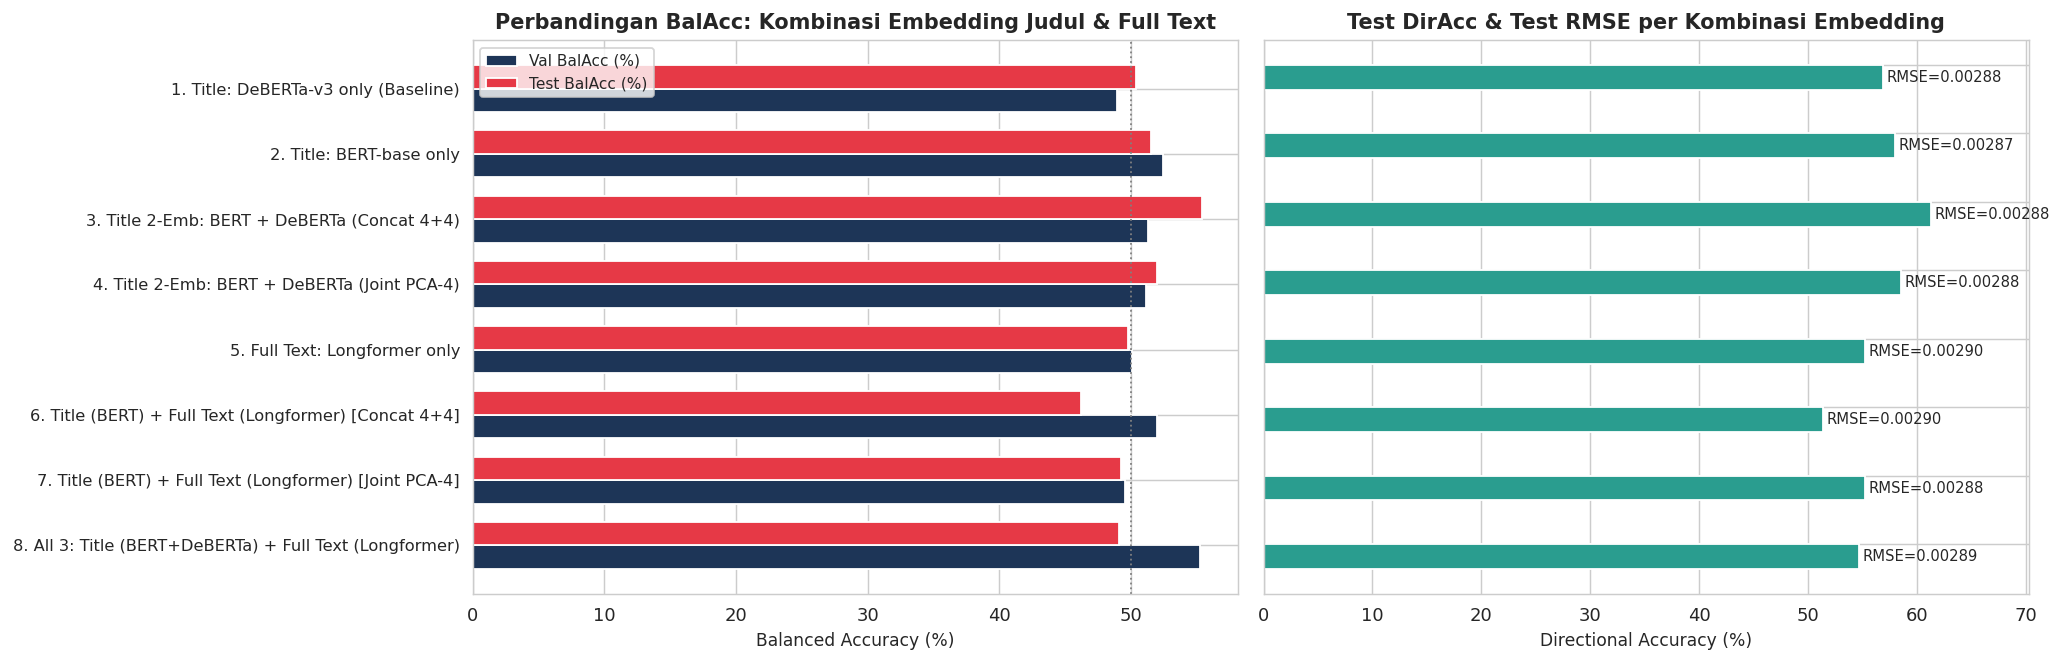

In [16]:
# 13.1 Ekstraksi Frozen BERT-base (Title) & Longformer (Full Text) dengan Cache + Zero Leakage
BERT_MODEL_NAME = "bert-base-uncased"
daily_bert_title = extract_daily_title_embeddings(
    BERT_MODEL_NAME,
    unique_titles,
    title_lists,
    batch_size=128,
    max_len=48,
    cache_path="bert_title_emb_cache.npz",
)
print(f"BERT Title daily matrix: {daily_bert_title.shape}")

N_PCA_BERT = 8
sc_bert = StandardScaler().fit(daily_bert_title[is_tr])
pca_bert = PCA(n_components=N_PCA_BERT, random_state=SEED).fit(sc_bert.transform(daily_bert_title[is_tr]))
bert_pca_feats = pca_bert.transform(sc_bert.transform(daily_bert_title))
bert_pca_cols = [f"bert_pca_{i}" for i in range(N_PCA_BERT)]
for i, c in enumerate(bert_pca_cols):
    df[c] = bert_pca_feats[:, i].astype(np.float32)
print(f"PCA Var Explained -> BERT-Title ({N_PCA_BERT}): {pca_bert.explained_variance_ratio_.sum():.3f}")


def extract_daily_longformer_embeddings(
    model_name: str,
    unique_texts: list,
    text_lists,
    batch_size: int = 8,
    max_len: int = 1536,
    cache_path: str = None,
):
    if cache_path and os.path.exists(cache_path):
        print(f"Memuat cache Longformer dari {cache_path}")
        data = np.load(cache_path, allow_pickle=True)
        txt_emb_map = dict(zip(data["texts"].tolist(), data["embs"]))
    else:
        print(f"Memuat frozen Longformer untuk full text: {model_name} (device={DEVICE}, max_len={max_len}) ...")
        tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
        mdl = AutoModel.from_pretrained(model_name).to(DEVICE)
        mdl.eval()
        for p in mdl.parameters():
            p.requires_grad = False

        use_amp = str(DEVICE).startswith("cuda")
        order = sorted(range(len(unique_texts)), key=lambda i: len(unique_texts[i]))
        sorted_texts = [unique_texts[i] for i in order]

        txt_emb_map = {}
        with torch.inference_mode():
            for i in tqdm(range(0, len(sorted_texts), batch_size), desc="Embedding Full Text (Longformer)"):
                batch_txt = sorted_texts[i : i + batch_size]
                enc = tok(
                    batch_txt,
                    padding=True,
                    truncation=True,
                    max_length=max_len,
                    return_tensors="pt",
                ).to(DEVICE)
                global_attention_mask = torch.zeros_like(enc["input_ids"])
                global_attention_mask[:, 0] = 1  # Global attention di [CLS] token
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    out = mdl(**enc, global_attention_mask=global_attention_mask).last_hidden_state
                out = out.float()
                if not torch.isfinite(out).all():
                    out = mdl(**enc, global_attention_mask=global_attention_mask).last_hidden_state.float()
                mask = enc["attention_mask"].unsqueeze(-1).float()
                emb = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
                emb_np = emb.cpu().numpy()
                for t_str, vec in zip(batch_txt, emb_np):
                    txt_emb_map[t_str] = vec

        del mdl, tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if cache_path:
            np.savez(
                cache_path,
                texts=np.array(list(txt_emb_map.keys()), dtype=object),
                embs=np.stack(list(txt_emb_map.values())),
            )
            print(f"Cache Longformer disimpan ke {cache_path}")

    hidden_dim = next(iter(txt_emb_map.values())).shape[0]
    daily_emb = np.zeros((len(text_lists), hidden_dim), dtype=np.float32)
    for row_idx, t_list in enumerate(text_lists):
        if t_list:
            daily_emb[row_idx] = np.mean([txt_emb_map[t] for t in t_list], axis=0)
    return daily_emb


fulltext_lists = [[p.strip() for p in s.split(" | ") if p.strip()] for s in df["norm_clean"]]
unique_fulltexts = sorted({t for sub in fulltext_lists for t in sub})
print(f"Total full-text unik: {len(unique_fulltexts):,} | Hari dengan full-text: {sum(1 for sub in fulltext_lists if sub)}/{len(df)}")

LONGFORMER_MODEL_NAME = "allenai/longformer-base-4096"
daily_longformer_ft = extract_daily_longformer_embeddings(
    LONGFORMER_MODEL_NAME,
    unique_fulltexts,
    fulltext_lists,
    batch_size=8,
    max_len=1536,
    cache_path="longformer_fulltext_emb_cache.npz",
)
print(f"Longformer Full-Text daily matrix: {daily_longformer_ft.shape}")

N_PCA_LONG = 8
sc_long = StandardScaler().fit(daily_longformer_ft[is_tr])
pca_long = PCA(n_components=N_PCA_LONG, random_state=SEED).fit(sc_long.transform(daily_longformer_ft[is_tr]))
long_pca_feats = pca_long.transform(sc_long.transform(daily_longformer_ft))
longformer_pca_cols = [f"longformer_pca_{i}" for i in range(N_PCA_LONG)]
for i, c in enumerate(longformer_pca_cols):
    df[c] = long_pca_feats[:, i].astype(np.float32)
print(f"PCA Var Explained -> Longformer-FullText ({N_PCA_LONG}): {pca_long.explained_variance_ratio_.sum():.3f}")


def add_joint_pca_cols(daily_mat_a: np.ndarray, daily_mat_b: np.ndarray, prefix: str, n_comp: int = 8) -> list[str]:
    sc_a = StandardScaler().fit(daily_mat_a[is_tr])
    sc_b = StandardScaler().fit(daily_mat_b[is_tr])
    joint = np.hstack([sc_a.transform(daily_mat_a), sc_b.transform(daily_mat_b)])
    pca_j = PCA(n_components=n_comp, random_state=SEED).fit(joint[is_tr])
    feats_j = pca_j.transform(joint)
    cols_j = [f"{prefix}_{i}" for i in range(n_comp)]
    for i, c in enumerate(cols_j):
        df[c] = feats_j[:, i].astype(np.float32)
    print(f"Joint PCA ({prefix}, n={n_comp}) Var Explained: {pca_j.explained_variance_ratio_.sum():.3f}")
    return cols_j


bert_deb_joint_cols = add_joint_pca_cols(daily_bert_title, daily_deberta_title, "joint_bert_deb_pca", n_comp=8)
bert_long_joint_cols = add_joint_pca_cols(daily_bert_title, daily_longformer_ft, "joint_bert_long_pca", n_comp=8)

# 13.2 Helper End-to-End Pipeline Varian (Stage 1 OOF Kronologis + Stage 2 RegularizedSeqLSTM)
# Pastikan seluruh skenario dievaluasi pada himpunan baris yang identik (df_model.index / tanggal valid TS)
VALID_MODEL_DATES = set(df_model[date_col].values)


def run_full_pipeline_variant(
    name: str,
    stage1_emb_cols: list[str],
    stage2_emb_cols: list[str],
    sent_prefix: str = "finbert",
    sent_cont_cols_in: list[str] = None,
    sent_s2_cols_in: list[str] = None,
    topic_cols_in: list[str] = None,
    use_ts: bool = True,
    use_text_inter: bool = True,
    seeds=ENSEMBLE_SEEDS,
) -> dict:
    wdf = df.copy()
    if sent_cont_cols_in is None:
        sent_cont_cols_in = fin_cont_cols
    if sent_s2_cols_in is None:
        sent_s2_cols_in = GRP_FINBERT_SENT
    if topic_cols_in is None:
        topic_cols_in = GRP_BERTOPIC

    # Aktifkan sumber sentimen untuk varian ini (apabila ada)
    if use_text_inter:
        wdf["kurs_pressure"] = wdf[f"{sent_prefix}_kurs_pressure"]
        wdf["sent_polarity"] = wdf[f"{sent_prefix}_sent_polarity"]
        wdf["sent_magnitude"] = wdf[f"{sent_prefix}_sent_magnitude"]
        wdf["sent_ratio"] = wdf[f"{sent_prefix}_sent_ratio"]

        # Re-fit Stage 1 LogisticRegression dengan TimeSeriesSplit(5) secara terisolasi
        s1_cols = list(dict.fromkeys(stage1_emb_cols + sent_cont_cols_in + topic_cols_in))
        assert len(s1_cols) > 0, f"Stage 1 fitur kosong pada {name}"

        X_s1_tr_v = wdf.loc[is_tr, s1_cols].reset_index(drop=True)
        oof_prob = np.full(len(y_tr_dir), 0.5, dtype=np.float64)
        oof_m = np.zeros(len(y_tr_dir), dtype=bool)
        for tr_f, ho_f in TimeSeriesSplit(n_splits=5).split(X_s1_tr_v):
            sc_f = StandardScaler().fit(X_s1_tr_v.iloc[tr_f])
            clf_f = make_best_s1().fit(sc_f.transform(X_s1_tr_v.iloc[tr_f]), y_tr_dir[tr_f])
            oof_prob[ho_f] = clf_f.predict_proba(sc_f.transform(X_s1_tr_v.iloc[ho_f]))[:, 1]
            oof_m[ho_f] = True

        sc_s1_v = StandardScaler().fit(wdf.loc[is_tr, s1_cols])
        clf_s1_v = make_best_s1().fit(sc_s1_v.transform(wdf.loc[is_tr, s1_cols]), y_tr_dir)
        p_va_v = clf_s1_v.predict_proba(sc_s1_v.transform(wdf.loc[is_va, s1_cols]))[:, 1]
        p_te_v = clf_s1_v.predict_proba(sc_s1_v.transform(wdf.loc[is_te, s1_cols]))[:, 1]

        s1_va_bal = round(float(balanced_accuracy_score(y_va_dir, (p_va_v >= 0.5).astype(int)) * 100), 2)
        s1_te_bal = round(float(balanced_accuracy_score(y_te_dir, (p_te_v >= 0.5).astype(int)) * 100), 2)
        s1_te_auc = round(float(roc_auc_score(y_te_dir, p_te_v)), 4)

        wdf.loc[is_tr, "pred_dir_prob"] = oof_prob
        wdf.loc[is_va, "pred_dir_prob"] = p_va_v
        wdf.loc[is_te, "pred_dir_prob"] = p_te_v
        wdf["pred_dir_class"] = (wdf["pred_dir_prob"] >= 0.5).astype(int)
        wdf["pred_dir_signed"] = 2.0 * wdf["pred_dir_prob"] - 1.0

        # Recompute Sent x Arah interaction features menggunakan Q70/Q90 Train set varian ini
        tr_mags_v = wdf.loc[is_tr & (wdf["has_news"] == 1), "sent_magnitude"].values
        q70_v = float(np.quantile(tr_mags_v, 0.70))
        q90_v = float(np.quantile(tr_mags_v, 0.90))

        wdf["sent_x_dir"] = wdf["kurs_pressure"] * wdf["pred_dir_signed"]
        wdf["sent_mag_x_dir"] = wdf["sent_magnitude"] * wdf["pred_dir_signed"]
        wdf["extreme_amp_x_dir"] = np.sign(wdf["sent_x_dir"]) * (np.abs(wdf["sent_x_dir"]) ** 2)

        d_up = wdf["pred_dir_signed"] > 0
        d_dn = wdf["pred_dir_signed"] < 0
        h_mask = wdf["sent_magnitude"] >= q70_v
        e_mask = wdf["sent_magnitude"] >= q90_v
        wdf["flag_naik_sent_tinggi"] = (d_up & h_mask).astype(int)
        wdf["flag_turun_sent_tinggi"] = (d_dn & h_mask).astype(int)
        wdf["flag_naik_ekstrem"] = (d_up & e_mask).astype(int)
        wdf["flag_turun_ekstrem"] = (d_dn & e_mask).astype(int)
        wdf["extreme_turun_pressure"] = wdf["flag_turun_ekstrem"] * (-wdf["sent_magnitude"])
        wdf["extreme_naik_pressure"] = wdf["flag_naik_ekstrem"] * (wdf["sent_magnitude"])
        wdf["sent_dir_5tier"] = (
            wdf["flag_naik_sent_tinggi"] + wdf["flag_naik_ekstrem"]
            - wdf["flag_turun_sent_tinggi"] - wdf["flag_turun_ekstrem"]
        )
        inter_cols_v = GRP_SENT_INTER
    else:
        s1_va_bal, s1_te_bal, s1_te_auc = np.nan, np.nan, np.nan
        inter_cols_v = []

    s2_cols = (
        (GRP_TS if use_ts else [])
        + stage2_emb_cols
        + sent_s2_cols_in
        + inter_cols_v
        + topic_cols_in
    )
    s2_cols = list(dict.fromkeys(s2_cols))
    assert len(set(s2_cols)) == len(s2_cols)

    frame = wdf.loc[wdf[date_col].isin(VALID_MODEL_DATES)].dropna(subset=s2_cols + ["log_ret"]).reset_index(drop=True)
    sd = build_sequences(frame, s2_cols, BEST_SEQ_LEN)
    sp_v = sd["split"]
    tr_v, va_v, te_v = sp_v == "train", sp_v == "val", sp_v == "test"

    ens = train_best_ensemble(
        sd["X"][tr_v], sd["y_s"][tr_v],
        sd["X"][va_v], sd["y_s"][va_v],
        sd["X"][te_v], sd["mu_y"], sd["std_y"],
        seeds=seeds, cfg=BEST_CFG,
    )
    m_tr_v = eval_reg("", sd["y_raw"][tr_v], ens["pred_tr"])
    m_va_v = eval_reg("", sd["y_raw"][va_v], ens["pred_va"])
    m_te_v = eval_reg("", sd["y_raw"][te_v], ens["pred_te"])
    seed_te_bals = [eval_reg("", sd["y_raw"][te_v], r["pred_te"])["BalAcc (%)"] for r in ens["runs"]]

    return {
        "Skenario": name,
        "#Fitur S2": len(s2_cols),
        "S1 Val Bal": s1_va_bal,
        "S1 Test Bal": s1_te_bal,
        "S1 Test AUC": s1_te_auc,
        "Train Bal (%)": m_tr_v["BalAcc (%)"],
        "Val Bal (%)": m_va_v["BalAcc (%)"],
        "Gap (Tr-Val)": round(m_tr_v["BalAcc (%)"] - m_va_v["BalAcc (%)"], 2),
        "Test Bal (%)": m_te_v["BalAcc (%)"],
        "Test Bal±sd": round(float(np.std(seed_te_bals)), 2),
        "Test Dir (%)": m_te_v["DirAcc (%)"],
        "Test F1 (%)": m_te_v["F1-Macro (%)"],
        "Test RMSE": m_te_v["RMSE"],
        "Test MAE": m_te_v["MAE"],
        "Test R2": m_te_v["R2"],
    }


emb_variants = [
    ("1. Title: DeBERTa-v3 only (Baseline)", deberta_pca_cols[:8], deberta_pca_cols[:4]),
    ("2. Title: BERT-base only", bert_pca_cols[:8], bert_pca_cols[:4]),
    ("3. Title 2-Emb: BERT + DeBERTa (Concat 4+4)", bert_pca_cols[:8] + deberta_pca_cols[:8], bert_pca_cols[:4] + deberta_pca_cols[:4]),
    ("4. Title 2-Emb: BERT + DeBERTa (Joint PCA-4)", bert_deb_joint_cols[:8], bert_deb_joint_cols[:4]),
    ("5. Full Text: Longformer only", longformer_pca_cols[:8], longformer_pca_cols[:4]),
    ("6. Title (BERT) + Full Text (Longformer) [Concat 4+4]", bert_pca_cols[:8] + longformer_pca_cols[:8], bert_pca_cols[:4] + longformer_pca_cols[:4]),
    ("7. Title (BERT) + Full Text (Longformer) [Joint PCA-4]", bert_long_joint_cols[:8], bert_long_joint_cols[:4]),
    ("8. All 3: Title (BERT+DeBERTa) + Full Text (Longformer)", bert_pca_cols[:4] + deberta_pca_cols[:4] + longformer_pca_cols[:4], bert_pca_cols[:3] + deberta_pca_cols[:3] + longformer_pca_cols[:3]),
]

emb_results = []
for v_name, s1_e, s2_e in emb_variants:
    print(f"Menjalankan ablasi embedding: {v_name} ...")
    emb_results.append(run_full_pipeline_variant(v_name, s1_e, s2_e))

emb_ablation_df = pd.DataFrame(emb_results).set_index("Skenario")
base_deb_test_bal = emb_ablation_df.loc["1. Title: DeBERTa-v3 only (Baseline)", "Test Bal (%)"]
base_deb_val_bal = emb_ablation_df.loc["1. Title: DeBERTa-v3 only (Baseline)", "Val Bal (%)"]
emb_ablation_df["Δ Val Bal"] = (emb_ablation_df["Val Bal (%)"] - base_deb_val_bal).round(2)
emb_ablation_df["Δ Test Bal"] = (emb_ablation_df["Test Bal (%)"] - base_deb_test_bal).round(2)

print("\n=== HASIL ABLATION KOMBINASI 2 EMBEDDING (STAGE 1 OOF + REGULARIZED SEQ-LSTM 5-SEED) ===")
display(emb_ablation_df)

# Visualisasi Perbandingan Embedding
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
y_idx = np.arange(len(emb_ablation_df))
h = 0.36

ax = axes[0]
ax.barh(y_idx + h / 2, emb_ablation_df["Val Bal (%)"], height=h, color="#1d3557", label="Val BalAcc (%)")
ax.barh(y_idx - h / 2, emb_ablation_df["Test Bal (%)"], height=h, color="#e63946", label="Test BalAcc (%)")
ax.axvline(50.0, color="gray", ls=":", lw=1.0)
ax.set_yticks(y_idx)
ax.set_yticklabels(emb_ablation_df.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Balanced Accuracy (%)")
ax.set_title("Perbandingan BalAcc: Kombinasi Embedding Judul & Full Text")
ax.legend(fontsize=8.5)

ax = axes[1]
ax.barh(y_idx + h / 2, emb_ablation_df["Test Dir (%)"], height=h, color="#2a9d8f", label="Test DirAcc (%)")
ax.set_yticks(y_idx)
ax.set_yticklabels([])
ax.invert_yaxis()
ax.set_xlabel("Directional Accuracy (%)")
ax.set_title("Test DirAcc & Test RMSE per Kombinasi Embedding")
for yi, (_, row) in enumerate(emb_ablation_df.iterrows()):
    ax.text(row["Test Dir (%)"] + 0.3, yi + h / 2, f"RMSE={row['Test RMSE']:.5f}", va="center", fontsize=8.2)
ax.set_xlim(right=emb_ablation_df["Test Dir (%)"].max() + 9.0)

plt.tight_layout()
plt.show()


Memuat frozen sentiment model (finbert_ft): ProsusAI/finbert (max_len=256) ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Sentiment (finbert_ft):   0%|          | 0/124 [00:00<?, ?it/s]

Cache sentiment disimpan ke finbert_fulltext_sent_cache.npz


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BERTopic (topic_title): 10 topik ditemukan -> 7 fitur
BERTopic (topic_ft): 8 topik ditemukan -> 7 fitur
Menjalankan ablasi granularitas: A0. TS Only (Non-Teks Baseline) ...
Menjalankan ablasi granularitas: A1. Title Saja (DeBERTa + FinBERT-Title + Topic-Title + TS) ...
Menjalankan ablasi granularitas: A2. Full Text Saja (Longformer + FinBERT-FT + Topic-FT + TS) ...
Menjalankan ablasi granularitas: A3. Both — Title (DeBERTa) + Full Text (Longformer) + TS ...
Menjalankan ablasi granularitas: A4. Both — Title (BERT+DeBERTa) + Full Text (Longformer) + TS ...
Menjalankan ablasi granularitas: B1. Text-Only: Title Saja ...
Menjalankan ablasi granularitas: B2. Text-Only: Full Text Saja ...
Menjalankan ablasi granularitas: B3. Text-Only: Both (Title + Full Text) ...

=== HASIL ABLATION TITLE vs FULL TEXT vs BOTH (ARSITEKTUR RegularizedSeqLSTM) ===


,Mode,#Fitur S2,S1 Val Bal,S1 Test Bal,Train Bal (%),Val Bal (%),Gap (Tr-Val),Test Bal (%),Test Bal±sd,Test Dir (%),Test F1 (%),Test RMSE,Test R2,Δ Test Bal vs TS,Δ Test Bal vs Title(+TS)
Skenario,,,,,,,,,,,,,,,
A0. TS Only (Non-Teks Baseline),Full (+TS),14,NaN,NaN,51.87,53.35,-1.48,52.14,0.70,58.56,44.13,0.002887,-0.0023,0.00,1.22
A1. Title Saja (DeBERTa + FinBERT-Title + Topic-Title + TS),Full (+TS),45,56.25,51.65,53.95,57.51,-3.56,50.92,4.42,55.80,47.21,0.002881,0.0016,-1.22,0.00
A2. Full Text Saja (Longformer + FinBERT-FT + Topic-FT + TS),Full (+TS),45,53.79,46.43,55.71,50.52,5.19,49.28,2.86,54.70,44.03,0.002883,0.0003,-2.86,-1.64
A3. Both — Title (DeBERTa) + Full Text (Longformer) + TS,Full (+TS),54,50.22,51.24,55.76,53.94,1.82,51.85,1.34,57.46,46.47,0.002897,-0.0094,-0.29,0.93
A4. Both — Title (BERT+DeBERTa) + Full Text (Longformer) + TS,Full (+TS),55,46.43,47.96,53.96,49.11,4.85,52.93,1.38,59.67,43.88,0.002879,0.0031,0.79,2.01
B1. Text-Only: Title Saja,Text-Only (No TS),31,56.25,51.65,53.18,50.89,2.29,53.30,1.99,59.12,47.55,0.002892,-0.0058,1.16,2.38
B2. Text-Only: Full Text Saja,Text-Only (No TS),31,53.79,46.43,51.13,49.03,2.10,51.97,1.79,58.56,43.26,0.002887,-0.0022,-0.17,1.05
B3. Text-Only: Both (Title + Full Text),Text-Only (No TS),40,50.22,51.24,53.82,51.49,2.33,48.75,1.91,55.25,39.66,0.002896,-0.0088,-3.39,-2.17


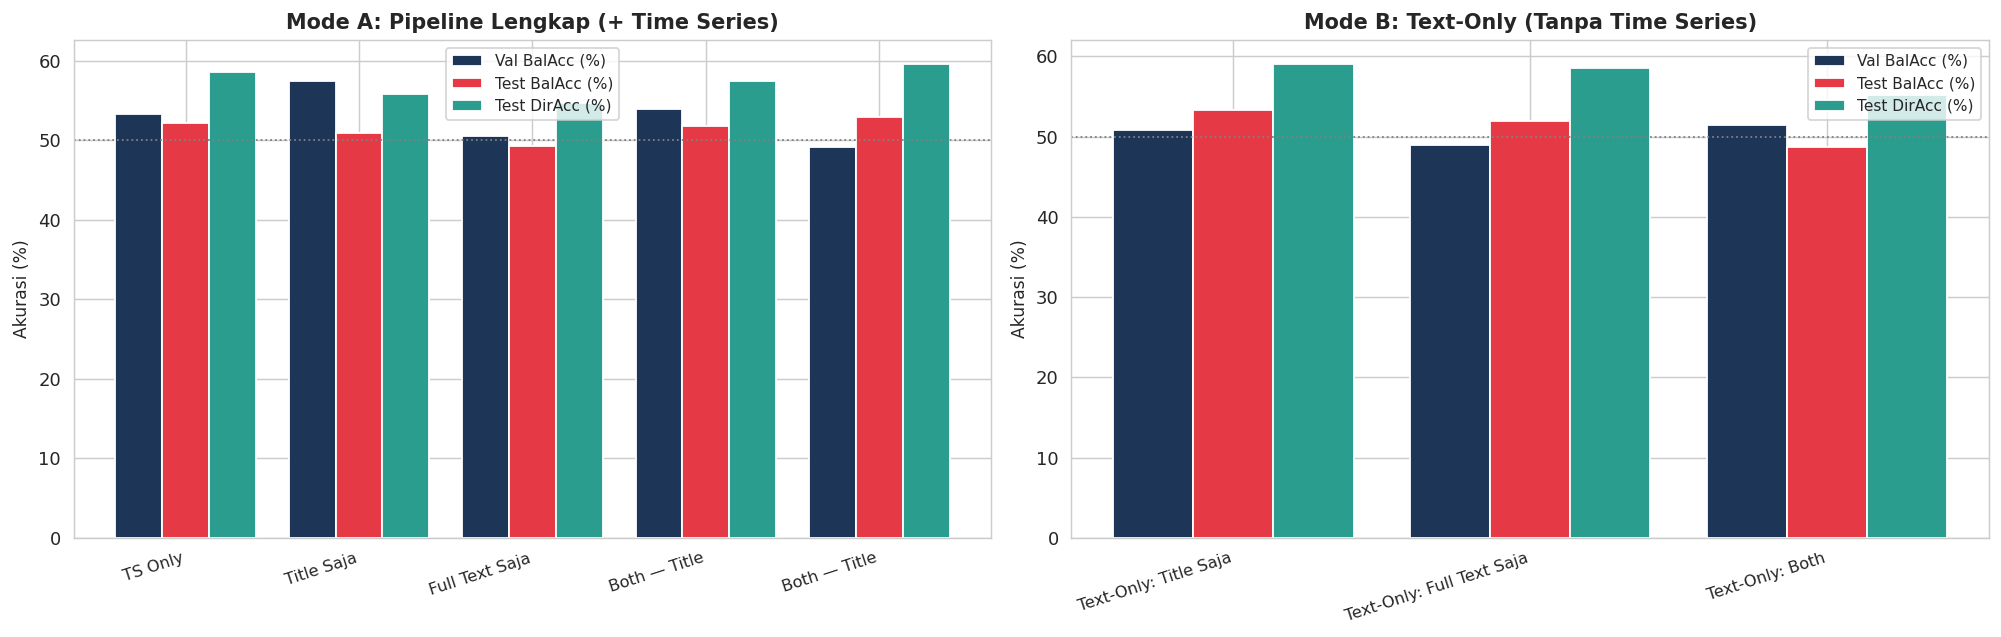

In [19]:
# 14.1 Ekstraksi FinBERT Sentiment & BERTopic Terpisah Khusus Full Text vs Title
def extract_daily_sentiment_cached(
    model_name: str,
    unique_texts: list,
    text_lists,
    prefix: str,
    batch_size: int = 32,
    max_len: int = 256,
    cache_path: str = None,
):
    if cache_path and os.path.exists(cache_path):
        print(f"Memuat cache sentiment {prefix} dari {cache_path}")
        data = np.load(cache_path, allow_pickle=True)
        sent_map = dict(zip(data["texts"].tolist(), [tuple(r) for r in data["probs"]]))
    else:
        print(f"Memuat frozen sentiment model ({prefix}): {model_name} (max_len={max_len}) ...")
        tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
        mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE)
        mdl.eval()
        for p in mdl.parameters():
            p.requires_grad = False

        id2lbl = {int(k): v.lower() for k, v in mdl.config.id2label.items()}
        pos_idx = next(k for k, v in id2lbl.items() if ("pos" in v) or ("bull" in v))
        neg_idx = next(k for k, v in id2lbl.items() if ("neg" in v) or ("bear" in v))
        neu_idx = next(k for k, v in id2lbl.items() if "neu" in v)

        use_amp = str(DEVICE).startswith("cuda")
        order = sorted(range(len(unique_texts)), key=lambda i: len(unique_texts[i]))
        sorted_texts = [unique_texts[i] for i in order]

        sent_map = {}
        with torch.inference_mode():
            for i in tqdm(range(0, len(sorted_texts), batch_size), desc=f"Sentiment ({prefix})"):
                batch_txt = sorted_texts[i : i + batch_size]
                enc = tok(batch_txt, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    logits = mdl(**enc).logits
                probs = torch.softmax(logits.float(), dim=-1).cpu().numpy()
                for t_str, pr in zip(batch_txt, probs):
                    sent_map[t_str] = (float(pr[pos_idx]), float(pr[neg_idx]), float(pr[neu_idx]))

        del mdl, tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if cache_path:
            np.savez(
                cache_path,
                texts=np.array(list(sent_map.keys()), dtype=object),
                probs=np.array(list(sent_map.values()), dtype=np.float32),
            )
            print(f"Cache sentiment disimpan ke {cache_path}")

    daily_pos = np.zeros(len(text_lists), dtype=np.float32)
    daily_neg = np.zeros(len(text_lists), dtype=np.float32)
    daily_neu = np.zeros(len(text_lists), dtype=np.float32)
    for row_idx, t_list in enumerate(text_lists):
        if t_list:
            arr = np.array([sent_map[t] for t in t_list], dtype=np.float32)
            daily_pos[row_idx], daily_neg[row_idx], daily_neu[row_idx] = arr.mean(axis=0)
        else:
            daily_neu[row_idx] = 1.0

    kp = (daily_neg - daily_pos).astype(np.float32)
    sp = (daily_pos - daily_neg).astype(np.float32)
    smag = np.abs(kp).astype(np.float32)
    srat = (daily_neg / (daily_pos + daily_neg + 1e-6)).astype(np.float32)

    return {
        f"{prefix}_pos": daily_pos,
        f"{prefix}_neg": daily_neg,
        f"{prefix}_neu": daily_neu,
        f"{prefix}_kurs_pressure": kp,
        f"{prefix}_sent_polarity": sp,
        f"{prefix}_sent_magnitude": smag,
        f"{prefix}_sent_ratio": srat,
    }


fin_ft_dict = extract_daily_sentiment_cached(
    "ProsusAI/finbert",
    unique_fulltexts,
    fulltext_lists,
    prefix="finbert_ft",
    batch_size=32,
    max_len=256,
    cache_path="finbert_fulltext_sent_cache.npz",
)
for k, v in fin_ft_dict.items():
    df[k] = v

# Gabungan rata-rata sentimen Title + Full Text untuk skenario 'Both'
for suf in ["pos", "neg", "neu", "kurs_pressure", "sent_polarity", "sent_magnitude", "sent_ratio"]:
    df[f"finbert_both_{suf}"] = (0.5 * (df[f"finbert_{suf}"] + df[f"finbert_ft_{suf}"])).astype(np.float32)

fin_ft_cont_cols = [
    "finbert_ft_kurs_pressure", "finbert_ft_sent_polarity", "finbert_ft_sent_magnitude",
    "finbert_ft_sent_ratio", "finbert_ft_pos", "finbert_ft_neg", "finbert_ft_neu", "has_news",
]
fin_ft_s2_cols = [
    "finbert_ft_kurs_pressure", "finbert_ft_sent_magnitude",
    "finbert_ft_pos", "finbert_ft_neg", "finbert_ft_neu",
]
fin_both_cont_cols = [
    "finbert_both_kurs_pressure", "finbert_both_sent_polarity", "finbert_both_sent_magnitude",
    "finbert_both_sent_ratio", "finbert_pos", "finbert_neg", "finbert_ft_pos", "finbert_ft_neg", "has_news",
]
fin_both_s2_cols = GRP_FINBERT_SENT + fin_ft_s2_cols


def extract_bertopic_features(docs: list[str], st_mdl, prefix: str) -> list[str]:
    n_mask = df["has_news"].values == 1
    tr_n_mask = is_tr & n_mask
    docs_news = [d if d.strip() else "no news" for d, m in zip(docs, n_mask) if m]

    with torch.no_grad():
        n_embs = st_mdl.encode(docs_news, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

    emb_full = np.zeros((len(df), n_embs.shape[1]), dtype=np.float32)
    emb_full[n_mask] = n_embs

    tr_d = [d if d.strip() else "no news" for d, m in zip(docs, tr_n_mask) if m]
    tr_e = emb_full[tr_n_mask]

    umap_m = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
    hdb_m = HDBSCAN(min_cluster_size=15, min_samples=5, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
    vec_m = CountVectorizer(stop_words="english", min_df=2, ngram_range=(1, 2))

    btm = BERTopic(
        embedding_model=st_mdl,
        umap_model=umap_m,
        hdbscan_model=hdb_m,
        vectorizer_model=vec_m,
        calculate_probabilities=True,
        verbose=False,
    )
    tr_top, _ = btm.fit_transform(tr_d, tr_e)
    all_top, all_pr = btm.transform(docs_news, emb_full[n_mask])
    all_pr = np.asarray(all_pr)
    if all_pr.ndim == 2 and all_pr.shape[1] == 0:
        all_pr = np.zeros((len(all_top), 1), dtype=np.float32)
    elif all_pr.ndim == 1:
        uniq_t = sorted([t for t in set(tr_top) if t != -1])
        oh = np.zeros((len(all_top), max(len(uniq_t), 1)), dtype=np.float32)
        tmap = {t: j for j, t in enumerate(uniq_t)}
        for r_i, tv in enumerate(all_top):
            if tv in tmap:
                oh[r_i, tmap[tv]] = 1.0
        all_pr = oh

    prob_full = np.zeros((len(df), all_pr.shape[1]), dtype=np.float32)
    prob_full[n_mask] = all_pr

    p_dim = min(5, prob_full.shape[1])
    sc_t = StandardScaler().fit(prob_full[is_tr])
    pca_t = PCA(n_components=p_dim, random_state=SEED).fit(sc_t.transform(prob_full[is_tr]))
    top_p = pca_t.transform(sc_t.transform(prob_full))
    p_cols = [f"{prefix}_pca_{i}" for i in range(p_dim)]
    for i, c in enumerate(p_cols):
        df[c] = top_p[:, i].astype(np.float32)

    u2 = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit(tr_e)
    u2_news = u2.transform(emb_full[n_mask])
    u_cols = [f"{prefix}_umap_0", f"{prefix}_umap_1"]
    df[u_cols[0]], df[u_cols[1]] = 0.0, 0.0
    df.loc[n_mask, u_cols[0]] = u2_news[:, 0].astype(np.float32)
    df.loc[n_mask, u_cols[1]] = u2_news[:, 1].astype(np.float32)

    n_top_found = int((btm.get_topic_info()["Topic"] != -1).sum())
    print(f"BERTopic ({prefix}): {n_top_found} topik ditemukan -> {len(p_cols) + len(u_cols)} fitur")
    return p_cols + u_cols


try:
    _st_ab = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE, local_files_only=True)
except Exception:
    _st_ab = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
for _p in _st_ab.parameters():
    _p.requires_grad = False
_st_ab.eval()

docs_title_only = [t if hn == 1 else "" for t, hn in zip(df["title_clean"], df["has_news"])]
docs_fulltext_only = [b[:1500] if hn == 1 else "" for b, hn in zip(df["norm_clean"], df["has_news"])]

topic_title_cols = extract_bertopic_features(docs_title_only, _st_ab, prefix="topic_title")
topic_ft_cols = extract_bertopic_features(docs_fulltext_only, _st_ab, prefix="topic_ft")

del _st_ab
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 14.2 Evaluasi Title vs Full Text vs Both menggunakan arsitektur fix-notebook (RegularizedSeqLSTM)
gran_specs = [
    # Mode A: Pipeline Penuh dengan Time Series (GRP_TS)
    dict(
        name="A0. TS Only (Non-Teks Baseline)",
        mode="Full (+TS)",
        s1_e=[], s2_e=[], sent_prefix="finbert",
        s1_sent=[], s2_sent=[], topic=[], use_ts=True, use_text_inter=False,
    ),
    dict(
        name="A1. Title Saja (DeBERTa + FinBERT-Title + Topic-Title + TS)",
        mode="Full (+TS)",
        s1_e=deberta_pca_cols[:8], s2_e=deberta_pca_cols[:4], sent_prefix="finbert",
        s1_sent=fin_cont_cols, s2_sent=GRP_FINBERT_SENT, topic=topic_title_cols, use_ts=True, use_text_inter=True,
    ),
    dict(
        name="A2. Full Text Saja (Longformer + FinBERT-FT + Topic-FT + TS)",
        mode="Full (+TS)",
        s1_e=longformer_pca_cols[:8], s2_e=longformer_pca_cols[:4], sent_prefix="finbert_ft",
        s1_sent=fin_ft_cont_cols, s2_sent=fin_ft_s2_cols, topic=topic_ft_cols, use_ts=True, use_text_inter=True,
    ),
    dict(
        name="A3. Both — Title (DeBERTa) + Full Text (Longformer) + TS",
        mode="Full (+TS)",
        s1_e=deberta_pca_cols[:8] + longformer_pca_cols[:8], s2_e=deberta_pca_cols[:4] + longformer_pca_cols[:4],
        sent_prefix="finbert_both", s1_sent=fin_both_cont_cols, s2_sent=fin_both_s2_cols,
        topic=GRP_BERTOPIC, use_ts=True, use_text_inter=True,
    ),
    dict(
        name="A4. Both — Title (BERT+DeBERTa) + Full Text (Longformer) + TS",
        mode="Full (+TS)",
        s1_e=bert_pca_cols[:4] + deberta_pca_cols[:4] + longformer_pca_cols[:4],
        s2_e=bert_pca_cols[:3] + deberta_pca_cols[:3] + longformer_pca_cols[:3],
        sent_prefix="finbert_both", s1_sent=fin_both_cont_cols, s2_sent=fin_both_s2_cols,
        topic=GRP_BERTOPIC, use_ts=True, use_text_inter=True,
    ),
    # Mode B: Text-Only (Tanpa Time Series GRP_TS) untuk isolasi sinyal teks murni
    dict(
        name="B1. Text-Only: Title Saja",
        mode="Text-Only (No TS)",
        s1_e=deberta_pca_cols[:8], s2_e=deberta_pca_cols[:4], sent_prefix="finbert",
        s1_sent=fin_cont_cols, s2_sent=GRP_FINBERT_SENT, topic=topic_title_cols, use_ts=False, use_text_inter=True,
    ),
    dict(
        name="B2. Text-Only: Full Text Saja",
        mode="Text-Only (No TS)",
        s1_e=longformer_pca_cols[:8], s2_e=longformer_pca_cols[:4], sent_prefix="finbert_ft",
        s1_sent=fin_ft_cont_cols, s2_sent=fin_ft_s2_cols, topic=topic_ft_cols, use_ts=False, use_text_inter=True,
    ),
    dict(
        name="B3. Text-Only: Both (Title + Full Text)",
        mode="Text-Only (No TS)",
        s1_e=deberta_pca_cols[:8] + longformer_pca_cols[:8], s2_e=deberta_pca_cols[:4] + longformer_pca_cols[:4],
        sent_prefix="finbert_both", s1_sent=fin_both_cont_cols, s2_sent=fin_both_s2_cols,
        topic=GRP_BERTOPIC, use_ts=False, use_text_inter=True,
    ),
]

gran_rows = []
for spc in gran_specs:
    print(f"Menjalankan ablasi granularitas: {spc['name']} ...")
    res_g = run_full_pipeline_variant(
        spc["name"],
        stage1_emb_cols=spc["s1_e"],
        stage2_emb_cols=spc["s2_e"],
        sent_prefix=spc["sent_prefix"],
        sent_cont_cols_in=spc["s1_sent"],
        sent_s2_cols_in=spc["s2_sent"],
        topic_cols_in=spc["topic"],
        use_ts=spc["use_ts"],
        use_text_inter=spc["use_text_inter"],
    )
    res_g["Mode"] = spc["mode"]
    gran_rows.append(res_g)

gran_df = pd.DataFrame(gran_rows).set_index("Skenario")
ts_bal = gran_df.loc["A0. TS Only (Non-Teks Baseline)", "Test Bal (%)"]
title_bal = gran_df.loc["A1. Title Saja (DeBERTa + FinBERT-Title + Topic-Title + TS)", "Test Bal (%)"]
gran_df["Δ Test Bal vs TS"] = (gran_df["Test Bal (%)"] - ts_bal).round(2)
gran_df["Δ Test Bal vs Title(+TS)"] = (gran_df["Test Bal (%)"] - title_bal).round(2)

col_order = [
    "Mode", "#Fitur S2", "S1 Val Bal", "S1 Test Bal", "Train Bal (%)",
    "Val Bal (%)", "Gap (Tr-Val)", "Test Bal (%)", "Test Bal±sd",
    "Test Dir (%)", "Test F1 (%)", "Test RMSE", "Test R2",
    "Δ Test Bal vs TS", "Δ Test Bal vs Title(+TS)",
]
gran_df = gran_df[col_order]
print("\n=== HASIL ABLATION TITLE vs FULL TEXT vs BOTH (ARSITEKTUR RegularizedSeqLSTM) ===")
display(gran_df)

# Visualisasi Mode A vs Mode B
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.0))
sub_a = gran_df[gran_df["Mode"] == "Full (+TS)"]
sub_b = gran_df[gran_df["Mode"] == "Text-Only (No TS)"]

for ax, sub, ttl in [
    (axes[0], sub_a, "Mode A: Pipeline Lengkap (+ Time Series)"),
    (axes[1], sub_b, "Mode B: Text-Only (Tanpa Time Series)"),
]:
    x = np.arange(len(sub))
    w = 0.27
    ax.bar(x - w, sub["Val Bal (%)"], w, label="Val BalAcc (%)", color="#1d3557")
    ax.bar(x, sub["Test Bal (%)"], w, label="Test BalAcc (%)", color="#e63946")
    ax.bar(x + w, sub["Test Dir (%)"], w, label="Test DirAcc (%)", color="#2a9d8f")
    ax.axhline(50.0, color="gray", ls=":", lw=1.0)
    short_labels = [lbl.split(". ", 1)[1].split(" (", 1)[0] for lbl in sub.index]
    ax.set_xticks(x)
    ax.set_xticklabels(short_labels, rotation=18, ha="right", fontsize=9)
    ax.set_ylabel("Akurasi (%)")
    ax.set_title(ttl)
    ax.legend(fontsize=8.5)

plt.tight_layout()
plt.show()
